# 6주차 본 실험 — GPU로 YOLOv8 vs RT-DETR 5-fold 비교
**v4.0 · CUDA GPU 학습·평가·속도 측정 · 전체 구현과 한글 폰트 포함**

Colab에서 **런타임 → 런타임 유형 변경 → T4 GPU 또는 사용 가능한 NVIDIA GPU**를 선택하세요.

- 모델: RT-DETR-L, 입력 크기는 기존 YOLO 설정에서 읽음(현재 기록 800), batch 2, **fold마다 100 epoch**, patience 0.
- `DEVICE='0'`은 첫 번째 GPU입니다. 셀 1에서 CUDA 사용 가능 여부와 작은 GPU 연산을 검사하고 GPU 이름·메모리를 표시합니다.
- Ultralytics **8.4.183**을 설치합니다. 이번 5주차 학습·평가 복구에 사용한 버전에 맞췄습니다. 재접속 후에도 같은 코드와 패키지 버전을 사용하세요.
- 5주차 루트는 `/content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020`입니다. 기존 분할·inner validation·YOLO 가중치를 검사합니다.
- GPU 실험은 새 폴더 `week6_rtdetr_gpu_full100_v4`에서 시작합니다. 이 실험에서 저장한 `last.pt`로 재개합니다.
- **셀 1~5 준비 → 셀 11에서 전체 5-fold 실행 → 셀 12~15 결과 확인** 순서입니다. Fold 1만 먼저 실행하려면 셀 9를 사용하세요. 셀 8의 3-epoch 시험은 기본 OFF입니다.
- `SESSION_EPOCHS=5`로 설정하면 총 100 epoch와 학습률 일정을 유지하면서 한 번에 새 5 epoch씩 진행합니다. 기본값 `None`은 연속 실행입니다.

AMP와 TF32는 끄고 FP32로 비교합니다. GPU에서도 RT-DETR의 CUDA backward 때문에 `deterministic=False`를 사용하며, seed를 고정해도 완전한 동일 결과를 보장하지 않습니다.


## 셀 1 — GPU·Drive 연결과 환경 설치
먼저 Colab 런타임 유형에서 GPU를 선택하세요. `DEVICE='0'`이 첫 번째 GPU입니다.

Colab에 설치된 PyTorch를 사용합니다. CUDA가 없거나 GPU 연결이 안 되면 여기서 원인을 표시합니다. GPU를 선택했는데도 `torch.version.cuda`가 None이면 CUDA 지원 PyTorch가 있는 새 GPU 런타임에서 시작하세요.

설치 뒤 현재 import된 패키지와 설치 버전이 다르다는 안내가 나오면 **세션 다시 시작** 후 셀 1부터 실행합니다. 학습·재개·평가 모두 Ultralytics 8.4.183으로 유지합니다.


In [3]:
import os, sys, subprocess, importlib.metadata as metadata
from pathlib import Path
DEVICE = '0'  # 첫 번째 CUDA GPU. Ultralytics에는 GPU 번호를 전달합니다.
ULTRALYTICS_VERSION = '8.4.183'
AVAILABLE_CPUS = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else (os.cpu_count() or 1)
CPU_THREADS = min(4, AVAILABLE_CPUS)  # 데이터 전처리 등에 쓰는 CPU thread 수
os.environ['OMP_NUM_THREADS'] = str(CPU_THREADS)
os.environ['MKL_NUM_THREADS'] = str(CPU_THREADS)

from google.colab import drive
if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    f'ultralytics=={ULTRALYTICS_VERSION}', 'pycocotools==2.0.11',
    'matplotlib', 'pandas', 'PyYAML', 'IPython'])

import torch, ultralytics, cv2, numpy as np, pandas as pd
if ultralytics.__version__ != ULTRALYTICS_VERSION:
    raise RuntimeError('설치 후 세션을 다시 시작하고 셀 1부터 실행하세요.')
for name, module in [('numpy', np), ('ultralytics', ultralytics), ('torch', torch)]:
    if module.__version__ != metadata.version(name):
        raise RuntimeError(f'{name} 설치 버전과 로드된 버전이 다릅니다. 세션을 다시 시작하세요.')
if torch.version.cuda is None:
    raise RuntimeError('현재 PyTorch는 CPU 전용입니다. Colab의 새 GPU 런타임에서 실행하세요.')
if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU에 연결되지 않았습니다. 런타임 유형에서 GPU를 선택한 뒤 다시 실행하세요.')
if not str(DEVICE).isdecimal() or int(DEVICE) >= torch.cuda.device_count():
    raise ValueError(f'DEVICE에는 사용 가능한 GPU 번호를 넣으세요. GPU 개수={torch.cuda.device_count()}')
GPU_INDEX = int(DEVICE)
torch.cuda.set_device(GPU_INDEX)
torch.set_num_threads(CPU_THREADS)
cv2.setNumThreads(0)
torch.set_float32_matmul_precision('highest')
torch.use_deterministic_algorithms(False)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = False

# 실제 CUDA 메모리 할당과 작은 연산이 가능한지 확인합니다.
probe = torch.ones(1, device=f'cuda:{GPU_INDEX}')
assert (probe + 1).item() == 2
torch.cuda.synchronize(GPU_INDEX)
del probe
props = torch.cuda.get_device_properties(GPU_INDEX)
print(f'실행 장치: cuda:{GPU_INDEX} | GPU: {props.name} | VRAM: {props.total_memory / 2**30:.1f} GiB')
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda, '| Ultralytics:', ultralytics.__version__)
print('CPU 전처리 threads:', CPU_THREADS, '| CUDA 실행 검사 통과')


실행 장치: cuda:0 | GPU: Tesla T4 | VRAM: 14.6 GiB
torch: 2.11.0+cu130 | CUDA: 13.0 | Ultralytics: 8.4.183
CPU 전처리 threads: 2 | CUDA 실행 검사 통과


## 셀 2 — 구현 코드와 한글 폰트 저장 공간
`/content/week6_code_gpu_v4`에 모듈과 한글 폰트를 준비합니다. 긴 문자열은 폰트·라이선스이며 모델이나 데이터가 아닙니다. 이 셀을 재실행하면 소스 목록이 초기화되므로 셀 3A~3F와 셀 4도 실행하세요.


In [4]:
import base64, zlib, hashlib, importlib
CODE_DIR = Path('/content/week6_code_gpu_v4'); CODE_DIR.mkdir(exist_ok=True)
SOURCES = {}
FONT_ASSETS = {'NanumGothic.ttf': '...', 'OFL.txt': 'eNqlV12TmzoSfdevUM3DVqaKcT52725V3hgbz1DXxr7AJJtHDLLRDSBWCDv+9/e0BP6aydbeu6lUYoTUffp092kxVe1Ry11p+Lv8nn/68PGDx6PniE+VbpXOjFQNf1ca035+//5wOEyassnxapKr+t5jB2lKHotO6L0o+Fw1hkdZLfBP09cwlO2FPj/gvydlSpmPb9jNGh6WR6Ga3e/q6vDlIh4fdd+VwwZ2vYLfa9FcHcbzhLG0lJ0DmKitOWRacCxUMhdNB+h9U2C/KQVPwgVftaJxmxdug8e/CN0RFx8nHyfO2HCWzOSqlTCyEZU6eDxrClrMqk7xbJ/JKttUgluqMj73f+OZ+cwGSrtcy9Z0k05WE6V371fzBWPs4a//YRb/Ooj4fBWlfBFOgygJLuHzB/7pn3wuNrrP9BEp//Cv/8shW8eBv3xcBKBF8J1C3FxtLZeveOTvEOA9J/aN4p2RdV9lBuQoXRUHWQhWiD1YbGuBQ7CSqwr02ULcC74lU61Wv4vcdJ410bcoU2O92be5FrZomdhu8cJCyfKsELXMbWYq2ex6Cdc5jNd130gjReeyBoOwvgcOZGqrhaBVpiiKrUZdA+Z3Lht+QL2W1l/H6+yIxPOuRFCFy31NRvCAnW2mTQPuS9m6ZkGt49EWJPiZL1AmKJrOBnCqRmcZaGC4x4IHqvpC0o9aFXIrnScGj4hEy01v6BQAV0eeoTTRLfQ/jB4t2Y0yvFMVSvRIi3Unqr3oJhwgmHXmAWxewQcdbI4c3SD3jnQKGu/zrCE4G3RKRUBEvRFFQb9uYADYe6WdO1f0sNeNTTfwC67LzNhXepAP1oDh7gSX4ia4t0gs6IEhYvv8vvNYqQ6oH23RkhEA1qIS2bnFyaPNATfHVlB1DKw7MrT4Ty+1sOWH+jlnAmsZ8jnqxEX/FwqoyVnWttWRYa8lUOW9tWILktx3xK05YVdWbqS+DABlMQvmYRSm4SpK2N2VXt0Bwxa1Q2jITCdsh2xlBf+nKF2CId+DrLNn5EHod939W9iJwBwnNeqmzvR3Sl+HpspLokPa6mauMuBQ9ToXzqGHQpBI8KBfLhNDyLb/EMrd68FwGQOx5FLetSIfito559nWODlm+Wk+dTBsE4NYyPoKy7LJqlHbbvkh6YBOkOqBpmvpR+e3qhG2hjp2Wb23/PETf+RzOXbfGz5v2qaG5pC1rLBNZTC8CiTJ4MFj1B/9BiJkelrgDw+jWFBdWIVRmBlYtvW6HQI6gXYr7JYCjxzmZdbsyCjqt85cpWGZZHKswGsyCDtrxIGLZi+1aohjCtbvTan06xA7uWuoxwS5EfQLTb2DPtb024i8bGSeVeygJWUR7l3DtbCibGgIpTkxPqTrChPcr4N4GSYJGoH/jU9X0WxoirXQtezsMEN9wq5AcPDeGNIiK9o0NyDHO+GNoAfXamPQxGCBZTSzT8xe+baHepr5JLpHz+6E8Apr0MreIMNH70r63AyBtFZXKo2+Oz3ai0J36Zad3aIiaLCNhGwVTQZKGdgqJBVy95mxj/c8EtIp2KtUNkqPFSOReYlzUNseFXIuHg8NzU+VgwO3RY3mHofaMDJgS1RbJOXT/X8/+Saho7VxdPyZeeHdDAyRQR0oIYxKCMl0kxNXhL3gZ62AHEPh3Ey/0Dur8ZA9N8tGYSv4wCepj8GZhwwDFH0hfphR7cq+zpoHSHlhL3MlflBPKE1kWgQtgLZa0m2mBkh0xnl7LQx+GdwppKiKzoZJ58gBTGzAJ25iTsmvxrfqxHhmmL9QeQmx3ktxOKsVqlUjO39HaahXSfl5TnDMvrnSaUY67cYF4HRc/GjBnjSc2tngJtReNeDQeSMSfBtgnrdUsOiyWxUdhgp2IPuDNDd0ZcHkpL4YKh801pYQQkwjgkS6pXtCcyEYFDRNzH/c2xtBM8Aeon1DwIeRy52uXey96kO6yaGDh9uDvYW4a2GtqMVFUygN3qjRClw1jLRj9MhuacfWH7lobTtn+fdGHVD7OzGwNMgf9p1xsLcwuxK+Aq1dm7jbw2162Dk94OYXx82Nvp3kCKbO4uS9NYI8VvedZeKyZZEHXJKQuNdXCieC9pCj8Gq63t7BLvuS/+zuxf7Xuxf/yd2Lne9et1MmpSkT+TRarr/qNgKKScZ7FAOFtFcSN/rt5UAeVWdUZ7q7MkKDfqerXJhMF364DGKWPgfueyxZzdOvfhzwMOHrePUlnAUzfucneL7z+NcwfV69pBw7Yj9Kv+EDgfvRN/5rGM08FvwbX1pJwlcxD5frRRjMPB5G08XLLIye+CPORSv64luGKYymK3t0MBUGODdnwDJ9xqP/GC7C9JvH52Eakc05jPp87cdpOH1Z+DFfv8TrFT4c/WgGs1EYzWN4CZZBlDKgmq7W3+Lw6Tn1cCjFosfT2J8FSz/+1SOEK4Qcc7tlApSwwYMvATHw7C8WHG/ZyQZ/Xi1m2P0YAL2PL0kHB+gtfx6f+Uv/KUjOdmmbi4CdGaADT0EUxP7C48k6mIb0A9SFcTBNLVegG8EvLELcKZLgtxcsYB8bXCAHz4F1Acw+/k6pNLiNOEKEZCddxekJytcwCTzux2ECCGwerwCXUogTlPQXUEj5iga8lBZae10Q2EWnmQtwFvgLGEwIxqu9E/YH/fb9DQ=='}
FONT_HASHES = {'NanumGothic.ttf': '76f45ef4a6bcff344c837c95a7dcc26e017e38b5846d5ae0cdcb5b86be2e2d31', 'OFL.txt': 'eeacf16032901d0ed0456876ec77b8f0fda6b3fecec7d972f8543eb602e6c30f'}
for filename, payload in FONT_ASSETS.items():
    data = zlib.decompress(base64.b64decode(payload))
    assert hashlib.sha256(data).hexdigest() == FONT_HASHES[filename]
    (CODE_DIR / filename).write_bytes(data)
print('소스/폰트 준비:', CODE_DIR)


소스/폰트 준비: /content/week6_code_gpu_v4


## 셀 3A — COCO 평가기 구현
**목적:** maxDet=300에서 AP를 직접 읽습니다. 잘못된 GT를 자동 삭제하지 않으며, 면적 0인 유한 예측은 FP로 유지합니다. 빈 예측·완벽 예측·중복 오탐을 확인하는 자체 검사를 포함합니다.

**실행 효과:** 함수 원문을 `SOURCES`에 등록합니다. 이 셀 자체로 학습하지 않습니다. 내용 수정 없이 실행하면 되고, 재실행해도 같은 항목을 교체하므로 중복 소스가 쌓이지 않습니다.

In [5]:
SOURCES['coco'] = r'''"""COCO AP at the explicitly selected maxDets, without default-only summarize()."""
import contextlib, io
import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


def evaluate(pred, rows, max_det=300):
    if len(pred)!=len(rows) or not rows: raise ValueError('Prediction/GT image counts must agree and be nonempty')
    if not isinstance(max_det,int) or max_det<=10: raise ValueError('max_det must be an integer >10')
    images=[{'id':i} for i in range(len(rows))]; cats=[{'id':1,'name':'pothole'}]
    ga=[]; da=[]
    for i,(p,r) in enumerate(zip(pred,rows)):
        gt=np.asarray(r['gt'],dtype=np.float64).reshape(-1,4)
        boxes=np.asarray(p['boxes'],dtype=np.float64).reshape(-1,4)
        scores=np.asarray(p['scores'],dtype=np.float64).reshape(-1)
        if len(boxes)!=len(scores) or not np.isfinite(scores).all() or np.any((scores<0)|(scores>1)):
            raise ValueError('Bad prediction scores: finite [0,1] scores and equal box count required')
        for arr,target in [(gt,ga),(boxes,da)]:
            role='GT' if target is ga else 'prediction'
            image=r.get('path',r.get('image',f'image_index={i}'))
            if not np.isfinite(arr).all():
                bad=np.flatnonzero(~np.isfinite(arr).all(axis=1))
                raise ValueError(f'{role}: nonfinite bbox in {image}; indices={bad.tolist()}, boxes={arr[bad].tolist()}')
            wh=arr[:,2:]-arr[:,:2]
            bad=np.flatnonzero(np.any(wh<=0,axis=1) if target is ga else np.any(wh<0,axis=1))
            if len(bad):
                raise ValueError(f'{role}: invalid bbox geometry in {image}; indices={bad.tolist()}, boxes={arr[bad].tolist()}')
            # Finite zero-area predictions remain unmatched detections (FP) under COCO.
            # Do not silently remove them or change GT annotations.
            for j,b in enumerate(arr):
                x,y,x2,y2=map(float,b); w,h=x2-x,y2-y
                ann={'id':len(target)+1,'image_id':i,'category_id':1,'bbox':[x,y,w,h],'area':w*h,'iscrowd':0}
                if target is da: ann['score']=float(scores[j])
                target.append(ann)
    if not ga: raise ValueError('No ground truth; overall AP is undefined')
    with contextlib.redirect_stdout(io.StringIO()):
        gt=COCO(); gt.dataset={'images':images,'categories':cats,'annotations':ga,'info':{}}; gt.createIndex()
        dt=COCO(); dt.dataset={'images':images,'categories':cats,'annotations':da,'info':{}}; dt.createIndex()
        ev=COCOeval(gt,dt,'bbox'); ev.params.imgIds=list(range(len(rows))); ev.params.catIds=[1]
        ev.params.maxDets=[1,10,max_det]
        ev.evaluate(); ev.accumulate()
    # precision shape: IoU x recall x class x area x maxDets
    mi=ev.params.maxDets.index(max_det)
    def ap(area='all',iou=None):
        ai=ev.params.areaRngLbl.index(area)
        values=ev.eval['precision'][:,:,:,ai,mi]
        if iou is not None: values=values[np.isclose(ev.params.iouThrs,iou)]
        values=values[values>-1]
        return float(values.mean()) if values.size else -1.
    result={'map':ap(),'map_50':ap(iou=.5),'map_75':ap(iou=.75),
            'map_small':ap('small'),'map_medium':ap('medium'),'map_large':ap('large')}
    if any(not np.isfinite(result[k]) or not 0<=result[k]<=1 for k in ['map','map_50','map_75']):
        raise RuntimeError(f'Invalid overall COCO AP; refusing model selection: {result}')
    return result,ev


def map_metrics(pred,rows,cfg): return evaluate(pred,rows,int(cfg['max_det']))[0]


def select_alpha(trials):
    if not trials: raise ValueError('No alpha trials')
    for r in trials:
        if not np.isfinite(r['map']) or not 0<=r['map']<=1:
            raise ValueError(f'Invalid validation mAP; cannot select alpha: {r}')
    return max(trials,key=lambda x:(x['map'],-x['alpha']))


def self_test():
    b=np.array([[0.,0.,20.,20.]])
    p=[{'boxes':b,'scores':np.array([.9])}]; t=[{'gt':b}]
    for cap in [100,300]:
        m,ev=evaluate(p,t,cap); assert np.isclose(m['map'],1.) and np.isclose(m['map_50'],1.)
        with contextlib.redirect_stdout(io.StringIO()): ev.summarize()
        if cap==100: assert np.isclose(ev.stats[0],m['map'])
        elif ev.stats[0]==-1: print('Reproduced: default summarize returns -1 at maxDets=300; corrected AP=1.0')
    empty=[{'boxes':np.empty((0,4)),'scores':np.empty(0)}]
    assert evaluate(empty,t)[0]['map']==0
    # A high-score false positive before the true detection lowers AP.
    p2=[{'boxes':np.array([[30,30,50,50],[0,0,20,20]]),'scores':np.array([.95,.9])}]
    assert np.isclose(evaluate(p2,t)[0]['map'],.5)
    # Same prediction, IoU=.6: only .50/.55/.60 thresholds pass -> mAP=.3.
    p3=[{'boxes':np.array([[5,0,25,20]]),'scores':np.array([.9])}]
    assert np.isclose(evaluate(p3,t)[0]['map'],.3)
    assert select_alpha([{'alpha':0.,'map':.4},{'alpha':1.,'map':.6}])['alpha']==1.
    try: select_alpha([{'alpha':0.,'map':-1.}])
    except ValueError: pass
    else: raise AssertionError('Invalid AP must stop alpha selection')
    zero=[{'boxes':np.array([[10,10,10,20],[0,0,20,20]]),'scores':np.array([.95,.9])}]
    assert np.isclose(evaluate(zero,t)[0]['map'],.5)  # invalid-region detection still contributes FP
    assert evaluate([{'boxes':np.array([[10,10,10,20]]),'scores':np.array([.9])}],t)[0]['map']==0
    for bad_gt in [np.array([[0,0,0,20]]),np.array([[0,0,np.nan,20]])]:
        try: evaluate(p,[{'gt':bad_gt,'path':'bad_gt_image.jpg'}])
        except ValueError as exc: assert 'GT' in str(exc) and 'bad_gt_image.jpg' in str(exc)
        else: raise AssertionError('Invalid GT must not be removed')
    try: evaluate([{'boxes':np.array([[20,0,10,20]]),'scores':np.array([.9])}],t)
    except ValueError as exc: assert 'prediction' in str(exc)
    else: raise AssertionError('Reversed prediction must fail')
    print('PASS: AP100/AP300, empty detections, FP ordering, IoU averaging, zero-area prediction FP, GT diagnostic, invalid-AP guard')

if __name__=='__main__': self_test()
'''


## 셀 3B — 데이터와 실험 검사 구현
**목적:** 기존 source/fold manifest, 원본 이미지·라벨 hash, 학습 가중치를 대조합니다. 알려진 group·중복 이미지가 split을 넘는지 확인하고 train/inner val만 학습용으로 복사합니다.

**실행 효과:** 함수 원문을 `SOURCES`에 등록합니다. 이 셀 자체로 학습하지 않습니다. 내용 수정 없이 실행하면 되고, 재실행해도 같은 항목을 교체하므로 중복 소스가 쌓이지 않습니다.

In [6]:
SOURCES['main_0'] = r'''"""Paired RT-DETR/YOLOv8 CV; all data splits come from the existing week5 run."""
from pathlib import Path
import contextlib, csv, gc, hashlib, importlib.metadata as md, json, os, platform
import random, re, shutil, subprocess, sys, time
import cv2
import numpy as np
import pandas as pd
from week6_coco import evaluate

VERSION = '4.0.0-gpu-full-experiment'
MODELS = ['YOLOv8', 'RT-DETR']
PLOT_METRICS = ['map','map_50','precision','recall','f1','fp_per_image']
METRICS = PLOT_METRICS + ['map_75','map_small','map_medium','map_large']


def load(p):
    return json.loads(Path(p).read_text(encoding='utf-8'))


def plain(o):
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o).__name__)


def dump(p, o):
    p=Path(p); p.parent.mkdir(parents=True, exist_ok=True)
    tmp=p.with_name(p.name+'.tmp')
    tmp.write_text(json.dumps(o, ensure_ascii=False, indent=2, default=plain, allow_nan=False), encoding='utf-8')
    os.replace(tmp,p)


def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()


def fingerprint(o):
    return hashlib.sha256(json.dumps(o,sort_keys=True,default=plain,allow_nan=False).encode()).hexdigest()


def table(p, rows):
    df=pd.DataFrame(rows); Path(p).parent.mkdir(parents=True,exist_ok=True)
    df.to_csv(p,index=False,encoding='utf-8-sig'); return df


def env():
    import torch
    packages={k:md.version(k) for k in ['ultralytics','torch','torchvision','numpy','opencv-python','pycocotools']}
    return {'packages':packages,'python':platform.python_version(),'cuda':torch.version.cuda,
            'gpu':torch.cuda.get_device_name(torch.cuda.current_device()) if torch.cuda.is_available() else 'CPU',
            'cudnn':torch.backends.cudnn.version(), 'module_version':VERSION,
            'cpu':platform.processor() or platform.machine(), 'logical_cpus':os.cpu_count(),
            'torch_threads':torch.get_num_threads()}


def resolve_device(requested='0'):
    """Resolve one CUDA device explicitly; never fall back to CPU for a GPU request."""
    import torch
    value=str(requested).strip().lower()
    if value=='cpu': return 'cpu'
    if value in {'gpu','cuda','auto'}: value='0'
    if value.startswith('cuda:'): value=value.split(':',1)[1]
    if not value.isdecimal(): raise ValueError('device는 cpu, auto 또는 GPU 번호 0 등으로 지정하세요.')
    if not torch.cuda.is_available() or int(value)>=torch.cuda.device_count():
        raise RuntimeError(f'요청 GPU {value}를 사용할 수 없습니다. Colab 런타임 유형에서 GPU를 선택하고 CUDA 지원 PyTorch 환경인지 확인하세요.')
    return str(int(value))


def configure_runtime(cfg):
    import torch
    device=resolve_device(cfg.get('device','0'))
    if device!=str(cfg.get('device','0')):
        raise ValueError('prepare()에서 확정한 device를 사용하세요.')
    threads=int(cfg.get('cpu_threads',min(4,os.cpu_count() or 1)))
    if threads<1: raise ValueError('cpu_threads는 1 이상이어야 합니다.')
    torch.set_num_threads(threads)
    cv2.setNumThreads(0)
    if device!='cpu':
        torch.cuda.set_device(int(device))
        torch.set_float32_matmul_precision('highest')
        torch.use_deterministic_algorithms(False)
        torch.backends.cuda.matmul.allow_tf32=False
        torch.backends.cudnn.allow_tf32=False
        torch.backends.cudnn.deterministic=False
    return device


def synchronize(device):
    if str(device)!='cpu':
        import torch
        torch.cuda.synchronize(int(device))


def freeze_versions(folder):
    now=env(); p=Path(folder)/'environment.json'
    if p.exists():
        old=load(p)
        if old['packages']!=now['packages'] or old['module_version']!=VERSION:
            raise RuntimeError('이 실험의 패키지/코드 버전이 바뀌었습니다. 원래 버전을 복원하거나 새 EXPERIMENT_NAME을 사용하세요.\n'+str(old['packages'])+'\n'+str(now['packages']))
    else: dump(p,now)
    return now


def canonical_label(text,w,h,label='label'):
    lines=[]
    for line_no,line in enumerate(text.splitlines(),1):
        if not line.strip(): continue
        try: v=np.asarray([float(x) for x in line.split()],np.float64)
        except ValueError as e: raise ValueError(f'{label}:{line_no}: 숫자 형식 오류') from e
        if len(v)!=5 or not np.isfinite(v).all() or v[0]!=0:
            raise ValueError(f'{label}:{line_no}: class=0,x,y,w,h의 5개 유한 숫자 필요')
        _,x,y,bw,bh=v; eps=1e-6
        if not (-eps<=x<=1+eps and -eps<=y<=1+eps and 0<bw<=1+eps and 0<bh<=1+eps):
            raise ValueError(f'{label}:{line_no}: 잘못된 정규화 좌표 {v.tolist()}; 자동 삭제하지 않습니다.')
        v[1:]=np.clip(v[1:],0,1); _,x,y,bw,bh=v
        x1,y1,x2,y2=np.clip([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h],[0,0,0,0],[w,h,w,h])
        if x2<=x1 or y2<=y1: raise ValueError(f'{label}:{line_no}: 면적 0 GT')
        values=[0,(x1+x2)/(2*w),(y1+y2)/(2*h),(x2-x1)/w,(y2-y1)/h]
        lines.append(' '.join(f'{a:.12g}' for a in values))
    canonical='\n'.join(lines)+'\n' if lines else ''
    # Re-read the staged text exactly as week5's audit_dataset did.
    gt=[]
    for line in lines:
        _,x,y,bw,bh=map(float,line.split())
        gt.append(np.clip([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h],[0,0,0,0],[w,h,w,h]).tolist())
    return canonical,np.asarray(gt,np.float32).reshape(-1,4)


def validate_splits(source, folds):
    n=len(source)
    if sorted(f['fold'] for f in folds)!=[1,2,3,4,5]: raise ValueError('fold 1~5가 모두 필요합니다.')
    for f in folds:
        parts=[f[s] for s in ['train','val','test']]
        if any(not a or len(a)!=len(set(a)) for a in parts): raise ValueError(f'fold{f["fold"]}: 빈 split/중복 index')
        if sorted(i for a in parts for i in a)!=list(range(n)): raise ValueError(f'fold{f["fold"]}: train/val/test 중복·누락')
        # Verify both the stored groups and directly visible duplicate identifiers.
        for key in ['group','pixel_sha256','family','provided_group']:
            sets=[{source[i].get(key) for i in a if source[i].get(key) is not None} for a in parts]
            if any(sets[a]&sets[b] for a,b in [(0,1),(0,2),(1,2)]):
                raise ValueError(f'fold{f["fold"]}: {key} 기준 split 누수')
    if sorted(i for f in folds for i in f['test'])!=list(range(n)):
        raise ValueError('모든 source가 정확히 한 번 outer test여야 합니다.')


def locate_runs(root, overrides=None):
    overrides=overrides or {}; found={}
    for k in range(1,6):
        specified=overrides.get(k,overrides.get(str(k)))
        options=[Path(specified)] if specified else sorted((Path(root)/f'fold{k}').glob('week5_*'))
        options=[p for p in options if (p/'detector/weights/best.pt').is_file() and (p/'dataset_manifest.json').is_file() and (p/'config.json').is_file()]
        if len(options)!=1:
            raise ValueError(f'fold{k}: YOLO 실행 폴더 {len(options)}개 발견: {[str(p) for p in options]}. '
                             'RUN_ROOT 또는 YOLO_RUN_OVERRIDES를 확인하세요. 임의 선택하지 않습니다.')
        found[k]=options[0]
    return found


def prepare(cfg):
    cfg=dict(cfg)
    cfg['device']=resolve_device(cfg.get('device','0'))
    cfg.setdefault('cpu_threads',min(4,os.cpu_count() or 1))
    cfg.setdefault('patience',20)
    configure_runtime(cfg)
    root=Path(cfg['week5_root']); data=Path(cfg['data_root']).resolve()
    for name in ['source_manifest.json','fold_indices.json']:
        if not (root/name).is_file():
            visible=[p.name for p in root.iterdir()] if root.is_dir() else []
            raise FileNotFoundError(f'{root/name} 필요. RUN_ROOT는 evaluation_repaired가 아닌 기존 학습 실행 루트입니다. 현재 보이는 파일: {visible[:30]}. 기존 분할을 임의로 새로 만들지 않습니다.')
    source=load(root/'source_manifest.json'); spec=load(root/'fold_indices.json'); folds=sorted(spec['folds'],key=lambda f:f['fold'])
    validate_splits(source,folds); old=locate_runs(root,cfg.get('yolo_run_overrides'))
    old_cfgs={k:load(p/'config.json') for k,p in old.items()}
    if cfg.get('imgsz') is None:
        sizes={int(c['imgsz']) for c in old_cfgs.values()}
        if len(sizes)!=1: raise ValueError('기존 fold별 imgsz가 다릅니다. 공통 imgsz를 명시하세요.')
        cfg['imgsz']=sizes.pop()
    if cfg.get('epochs') is None:
        budgets={int(c['yolo_epochs']) for c in old_cfgs.values()}
        if len(budgets)!=1: raise ValueError('기존 epoch budget이 다릅니다. epochs를 명시하세요.')
        cfg['epochs']=budgets.pop()
    if not cfg.get('smoke_only'):
        budgets={int(c['yolo_epochs']) for c in old_cfgs.values()}
        sizes={int(c['imgsz']) for c in old_cfgs.values()}
        if budgets!={int(cfg['epochs'])}:
            raise ValueError(f'본 비교는 YOLO와 같은 최대 epoch 예산이 필요합니다: YOLO={budgets}, RT-DETR={cfg["epochs"]}')
        if sizes!={int(cfg['imgsz'])}:
            raise ValueError(f'본 비교는 YOLO와 같은 입력 크기가 필요합니다: YOLO={sizes}, RT-DETR={cfg["imgsz"]}')
    if int(cfg['imgsz'])%32 or cfg['imgsz']<32: raise ValueError('imgsz는 32의 양수 배수 필요')
    if cfg['max_det']!=300: raise ValueError('이 노트북은 두 모델 공통 maxDet=300을 사용합니다.')
    if not 0<cfg['proposal_conf']<.01: raise ValueError('AP용 proposal_conf는 .001 권장')
    if cfg['batch']<1 or cfg['epochs']<1: raise ValueError('batch/epochs 양수 필요')
    if cfg['amp'] or cfg['deterministic']: raise ValueError('RT-DETR 안정성 기본값 amp=False, deterministic=False를 유지하세요.')
    if not re.fullmatch(r'[A-Za-z0-9_-]+',cfg['experiment_name']): raise ValueError('EXPERIMENT_NAME은 영문/숫자/_/-만 사용')
    out=Path(cfg['output_root'])/cfg['experiment_name']; rows=[]
    print(f'원본 이미지·라벨 검사: {len(source)}장',flush=True)
    for i,s in enumerate(source):
        rel=Path(s['relative_path']); p=(data/rel).resolve()
        if not p.is_relative_to(data) or rel.is_absolute(): raise ValueError('data_root 바깥 경로')
        label=p.parent.parent/'labels'/(p.stem+'.txt')
        if not p.is_file() or not label.is_file(): raise FileNotFoundError(f'이미지/라벨 누락: {p} | {label}')
        if sha(label)!=s['label_sha256']: raise ValueError(f'5주차 이후 원본 라벨 변경: {label}')
        im=cv2.imread(str(p))
        if im is None: raise ValueError(f'이미지 디코딩 실패: {p}')
        pixel=hashlib.sha256(np.asarray(im.shape,dtype=np.int64).tobytes()+im.tobytes()).hexdigest()
        if pixel!=s['pixel_sha256']: raise ValueError(f'5주차 이후 이미지 변경: {p}')
        h,w=im.shape[:2]; labeltext,gt=canonical_label(label.read_text(),w,h,label)
        rows.append({'index':i,'path':str(p),'relative_path':rel.as_posix(),'group':s['group'],'gt':gt,
                     'canonical_label':labeltext,'canonical_hash':hashlib.sha256(labeltext.encode()).hexdigest(),
                     'pixel_sha256':pixel,'width':w,'height':h})
        if (i+1)%100==0 or i+1==len(source): print(f'  확인 {i+1}/{len(source)}',flush=True)
    provenance=[]
    for f in folds:
        k=f['fold']; manifest=load(old[k]/'dataset_manifest.json')
        for split in ['train','val','test']:
            mr=[r for r in manifest if r['split']==split]
            ids=[int(Path(r['path']).stem) for r in mr]
            if sorted(ids)!=sorted(f[split]): raise ValueError(f'fold{k} {split}: 기존 YOLO 학습/평가 데이터 불일치')
            if not sum(len(rows[i]['gt']) for i in ids): raise ValueError(f'fold{k} {split}: GT 없음')
            for r,i in zip(mr,ids):
                if r['label_sha256']!=rows[i]['canonical_hash'] or r['pixel_sha256']!=rows[i]['pixel_sha256']:
                    raise ValueError(f'fold{k}, source {i}: 기존 staged 라벨/이미지와 불일치')
        c=old_cfgs[k]
        if c.get('yolo_weights'): raise ValueError(f'fold{k}: 기존 YOLO가 외부 fine-tuned 가중치에서 시작했습니다. 누수 검토가 필요합니다.')
        if not str(c.get('yolo_init','')).startswith('yolov8'): raise ValueError(f'fold{k}: YOLOv8 초기 가중치가 아닙니다.')
        provenance.append({'fold':k,'run_dir':str(old[k]),'weights':str(old[k]/'detector/weights/best.pt'),
            'weights_sha256':sha(old[k]/'detector/weights/best.pt'),'config_sha256':sha(old[k]/'config.json'),
            'manifest_sha256':sha(old[k]/'dataset_manifest.json'),'yolo_init':c['yolo_init'],
            'train_imgsz':c['imgsz'],'epoch_budget':c['yolo_epochs'],'train_batch':c.get('yolo_batch'),
            'seed':c['seed']})
    identity={'cfg':cfg,'source_sha':sha(root/'source_manifest.json'),'fold_sha':sha(root/'fold_indices.json'),
              'yolo_provenance':provenance,'code_version':VERSION,'module_sha':sha(__file__),
              'evaluator_sha':sha(Path(__file__).with_name('week6_coco.py'))}
    fid=fingerprint(identity)
    if (out/'experiment.json').exists() and load(out/'experiment.json')['fingerprint']!=fid:
        raise ValueError('같은 EXPERIMENT_NAME의 설정/데이터/가중치/코드가 바뀌었습니다. 새 이름으로 실험하세요.')
    out.mkdir(parents=True,exist_ok=True); dump(out/'experiment.json',{'fingerprint':fid,**identity})
    dump(out/'fold_indices.json',spec); dump(out/'yolo_provenance.json',provenance)
    table(out/'split_summary.csv',[{'fold':f['fold'],**{s:len(f[s]) for s in ['train','val','test']},
        'train_objects':sum(len(rows[i]['gt']) for i in f['train'])} for f in folds])
    ctx={'cfg':cfg,'root':out,'folds':folds,'rows':rows,'old_runs':old,'old_cfgs':old_cfgs,'fingerprint':fid,'yolo_provenance':provenance}
    print('검사 완료. 같은 5-fold + 같은 inner validation을 사용합니다.')
    print('imgsz =',cfg['imgsz'],'| RT-DETR 최대 epochs =',cfg['epochs'],'| 결과:',out)
    print('실행 장치 =',cfg['device'],'| CPU threads =',cfg['cpu_threads'],
          '| patience =',cfg['patience'],'| 실제 완료 epoch는 fold별로 기록합니다.')
    print('기존 YOLO 학습 조건:',[(p['fold'],p['yolo_init'],p['train_imgsz'],p['epoch_budget']) for p in provenance])
    return ctx


def stage(ctx,k):
    cfg=ctx['cfg']; f=ctx['folds'][k-1]
    dst=Path(cfg['local_stage_root'])/ctx['fingerprint'][:16]/f'fold{k}'
    expected={}
    for split in ['train','val']:
        for sub in ['images','labels']: (dst/split/sub).mkdir(parents=True,exist_ok=True)
        expected[split]=set()
        for i in f[split]:
            r=ctx['rows'][i]; name=f'{i:06d}'+Path(r['path']).suffix.lower(); expected[split].add(name)
            # Refresh the local cache from audited source; never mutate original files.
            shutil.copy2(r['path'],dst/split/'images'/name)
            (dst/split/'labels'/f'{i:06d}.txt').write_text(r['canonical_label'])
        if {p.name for p in (dst/split/'images').iterdir()}!=expected[split]:
            raise ValueError(f'알 수 없는 staged 이미지: {dst/split}. 해당 실험 staging 경로를 확인하세요.')
    import yaml
    (dst/'data.yaml').write_text(yaml.safe_dump({'path':str(dst),'train':'train/images','val':'val/images',
                                               'names':{0:'pothole'}},sort_keys=False))
    return dst/'data.yaml'


def clean_gpu(device='cpu'):
    import torch
    gc.collect()
    if str(device)!='cpu' and torch.cuda.is_available(): torch.cuda.empty_cache()


def get_init(ctx):
    from ultralytics import RTDETR
    dst=ctx['root']/'pretrained'/ctx['cfg']['rtdetr_init']; marker=dst.parent/'provenance.json'
    dst.parent.mkdir(parents=True,exist_ok=True)
    if not dst.is_file():
        model=RTDETR(ctx['cfg']['rtdetr_init'])
        src=Path(model.ckpt_path)
        if not src.is_file(): raise FileNotFoundError(f'사전학습 파일 다운로드 확인 필요: {src}')
        shutil.copy2(src,dst); del model; clean_gpu(ctx['cfg']['device'])
    current={'name':ctx['cfg']['rtdetr_init'],'sha256':sha(dst)}
    if marker.exists() and load(marker)!=current: raise ValueError('RT-DETR 초기 가중치가 바뀌었습니다.')
    dump(marker,current); return dst


'''


## 셀 3C — GPU 학습·checkpoint 재개·나눠 실행 구현
각 fold는 같은 COCO 사전학습 파일에서 시작합니다. 학습 장치를 명시하며 GPU 메모리 사용량을 기록합니다. 재개 시 해당 fold의 epoch와 optimizer가 저장된 last.pt를 사용합니다.

`SESSION_EPOCHS`에 도달하면 epoch 끝에서 checkpoint를 확인한 뒤 일시정지합니다. 전체 100-epoch 예산과 scheduler를 유지합니다. 실제 오류와 NaN·Inf는 중단합니다. 이 셀은 함수를 등록합니다.


In [7]:
SOURCES['main_1'] = r'''class SmokePause(RuntimeError):
    """Intentional interruption after a durable checkpoint; smoke run only."""


class SessionPause(RuntimeError):
    """An epoch-boundary pause, not training completion or early stopping."""


def loss_snapshot(losses):
    """Validate dict/list/tensor/array losses and return named scalar means.

    trainer.tloss may be a dictionary of scalar tensors.
    Detach and transfer each leaf before NumPy conversion; never pass the whole
    dictionary to torch.isfinite(). Empty or nonfinite losses are errors.
    """
    from collections.abc import Mapping
    result={}
    def visit(value, name):
        if isinstance(value, Mapping):
            if not value: raise ValueError(f'{name}: empty loss mapping')
            for key,item in value.items(): visit(item,f'{name}/{key}')
        elif isinstance(value,(list,tuple)):
            if not value: raise ValueError(f'{name}: empty loss sequence')
            for index,item in enumerate(value): visit(item,f'{name}/{index}')
        else:
            if value is None: raise ValueError(f'{name}: loss is None')
            if hasattr(value,'detach'): value=value.detach().float().cpu().numpy()
            array=np.asarray(value,dtype=np.float64)
            if not array.size: raise ValueError(f'{name}: empty loss array')
            if not np.isfinite(array).all(): raise FloatingPointError(f'{name}: NaN/Inf loss')
            result[name]=float(array.mean())
    visit(losses,'loss')
    return result


def train_fold(ctx,k,pause_after_epoch=None,max_new_epochs=None):
    import torch
    from ultralytics import RTDETR
    cfg=ctx['cfg']; out=ctx['root']/f'fold{k}'; out.mkdir(exist_ok=True)
    device=configure_runtime(cfg)
    if max_new_epochs is not None and (not isinstance(max_new_epochs,int) or max_new_epochs<1):
        raise ValueError('max_new_epochs는 None 또는 양의 정수입니다. 전체 epochs는 바꾸지 않습니다.')
    if pause_after_epoch is not None and not cfg.get('smoke_only'):
        raise ValueError('의도적 중단 검사는 별도 smoke 실험에서만 허용합니다.')
    freeze_versions(ctx['root']); best=out/'detector/weights/best.pt'; last=best.with_name('last.pt')
    marker=out/'training_complete.json'; progress=out/'training_progress.json'
    if marker.exists():
        record=load(marker)
        if not best.is_file() or sha(best)!=record['best_sha256']: raise ValueError(f'fold{k}: 완료 가중치 변경/누락')
        print(f'fold{k}: RT-DETR 학습 완료 가중치 재사용',flush=True); return best
    data=stage(ctx,k); init=get_init(ctx)
    previous=load(progress) if progress.exists() else {}; prior_seconds=float(previous.get('logged_wall_seconds',0))
    t0=time.perf_counter(); previous_epoch=int(previous.get('epoch',0)); resume=False
    if last.exists():
        ckpt=torch.load(last,map_location='cpu',weights_only=False)
        saved_epoch=int(ckpt.get('epoch',-1))+1
        finished=best.is_file() and ((ckpt.get('epoch',0)==-1 and ckpt.get('optimizer') is None)
                                   or saved_epoch>=cfg['epochs'])
        if finished:
            dump(marker,{'best_sha256':sha(best),'logged_wall_seconds':prior_seconds,
                         'recovered_after_finalization':True,'epochs_completed':max(previous_epoch,saved_epoch)})
            del ckpt; print(f'fold{k}: 종료 처리된 checkpoint 복구'); return best
        resume=ckpt.get('epoch',-1)>=0 and ckpt.get('optimizer') is not None
        del ckpt
        if not resume: raise ValueError(f'{last}: 재개 가능한 학습 checkpoint가 아닙니다.')
    elif (out/'detector/results.csv').exists():
        raise FileNotFoundError('학습 기록은 있으나 last.pt가 없습니다. 완료되지 않은 실행입니다. 새 EXPERIMENT_NAME으로 시작하세요.')
    model=RTDETR(str(last if resume else init))
    def started(trainer):
        start=int(trainer.start_epoch)
        if resume and start<=0: raise RuntimeError('resume=True인데 시작 epoch가 0입니다.')
        record={'resume':resume,'start_epoch_zero_based':start,'weights':str(last if resume else init),
                'time':time.strftime('%Y-%m-%d %H:%M:%S'),'device':device,
                'cpu_threads':cfg['cpu_threads'],'epoch_budget':cfg['epochs']}
        dump(out/('resume_verified.json' if resume else 'training_start.json'),record)
        configure_runtime(cfg)  # Ultralytics select_device may reset torch thread count.
        # Standard resume may not restore EarlyStopping's best_epoch. Preserve it for chunked sessions.
        if resume and int(previous.get('epoch',-1))==start:
            stopper=getattr(trainer,'stopper',None)
            for key,value in previous.get('early_stopping',{}).items():
                if stopper is not None and hasattr(stopper,key): setattr(stopper,key,value)
        if device!='cpu': torch.cuda.reset_peak_memory_stats(int(device))
        if (out/'last_error.json').exists(): (out/'last_error.json').unlink()
    def batch_guard(trainer):
        if int(trainer.batch_size)!=cfg['batch']:
            raise RuntimeError('메모리 부족으로 Ultralytics가 batch를 바꾸었습니다. 같은 5-fold 조건을 유지하려면 batch를 낮추고 새 EXPERIMENT_NAME으로 시작하세요.')
    def heartbeat(trainer):
        try:
            losses=loss_snapshot(trainer.tloss)
        except (ValueError,TypeError,FloatingPointError) as exc:
            raise type(exc)(f'fold{k} epoch {trainer.epoch+1}: {exc}') from exc
        stopper=getattr(trainer,'stopper',None)
        stop_state={key:getattr(stopper,key) for key in ['best_fitness','best_epoch','possible_stop']
                    if stopper is not None and hasattr(stopper,key)}
        dump(progress,{'epoch':int(trainer.epoch+1),'logged_wall_seconds':prior_seconds+time.perf_counter()-t0,
                       'status':'training','last_checkpoint':str(last),'losses':losses,'device':device,
                       'early_stopping':stop_state})
        elapsed=time.perf_counter()-t0
        done=int(trainer.epoch+1)-int(trainer.start_epoch)
        remaining=max(0,cfg['epochs']-int(trainer.epoch+1))
        print(f'fold{k} epoch {trainer.epoch+1}/{cfg["epochs"]} 저장 | {device} | '
              f'이번 실행 평균 {elapsed/max(done,1)/60:.1f}분/epoch | '
              f'최대 예산까지 단순 잔여 {elapsed/max(done,1)*remaining/3600:.1f}시간 '
              '(조기 종료·outer 평가·중단 시간 미반영)',flush=True)
    def finished(trainer):
        if not best.is_file(): raise FileNotFoundError(best)
        dump(marker,{'best_sha256':sha(best),'epochs_completed':int(trainer.epoch+1),
                     'logged_wall_seconds':prior_seconds+time.perf_counter()-t0,'recovered_after_finalization':False,
                     'peak_allocated_gib_last_session':float(torch.cuda.max_memory_allocated(int(device))/2**30)
                         if device!='cpu' else None,'device':device,'cpu_threads':cfg['cpu_threads'],
                     'epoch_budget':cfg['epochs'],'patience':cfg['patience']})
        state=load(progress) if progress.exists() else {}
        dump(progress,{**state,'status':'completed','epoch':int(trainer.epoch+1),'device':device})
    def smoke_pause(trainer):
        proof=out/'intentional_pause.json'
        if pause_after_epoch is not None and not proof.exists() and trainer.epoch+1>=pause_after_epoch:
            if not last.is_file(): raise FileNotFoundError('중단 검사 전에 last.pt가 저장되지 않았습니다.')
            ckpt=torch.load(last,map_location='cpu',weights_only=False)
            valid=ckpt.get('epoch',-1)>=0 and ckpt.get('optimizer') is not None
            record={'checkpoint_epoch':int(ckpt.get('epoch',-1)),
                    'optimizer_present':ckpt.get('optimizer') is not None,'last_sha256':sha(last)}
            del ckpt
            if not valid: raise RuntimeError('시험 checkpoint에 epoch/optimizer가 없어 재개 불가능합니다.')
            dump(proof,record)
            raise SmokePause('시험 실행: checkpoint 저장 후 의도적으로 중단했습니다. 곧 resume합니다.')
    def session_pause(trainer):
        done=int(trainer.epoch+1)-int(trainer.start_epoch)
        # Allow normal finalization at the full budget or an actual early stop.
        if max_new_epochs is None or done<max_new_epochs or trainer.epoch+1>=cfg['epochs'] or bool(getattr(trainer,'stop',False)):
            return
        if not last.is_file(): raise FileNotFoundError('나눠 실행하기 전에 last.pt 저장을 확인할 수 없습니다.')
        ckpt=torch.load(last,map_location='cpu',weights_only=False)
        valid=int(ckpt.get('epoch',-1))==int(trainer.epoch) and ckpt.get('optimizer') is not None
        del ckpt
        if not valid: raise RuntimeError('재개 가능한 epoch/optimizer checkpoint가 없어 일시정지하지 않습니다.')
        dump(progress,{**load(progress),'status':'paused','session_epochs':done})
        raise SessionPause(f'fold{k}: 총 {trainer.epoch+1}/{cfg["epochs"]} epoch 저장 후 일시정지. 같은 셀을 다시 실행하면 이어갑니다.')
    model.add_callback('on_train_start',started)
    model.add_callback('on_train_epoch_start',batch_guard)
    model.add_callback('on_fit_epoch_end',heartbeat); model.add_callback('on_train_end',finished)
    model.add_callback('on_fit_epoch_end',smoke_pause)
    model.add_callback('on_fit_epoch_end',session_pause)
    print(f'fold{k}: '+('last.pt에서 학습 재개' if resume else '공통 COCO 사전학습 가중치에서 새로 학습'),flush=True)
    args=dict(data=str(data),imgsz=cfg['imgsz'],epochs=cfg['epochs'],batch=cfg['batch'],
        device=cfg['device'],workers=cfg['workers'],seed=int(ctx['old_cfgs'][k]['seed']),
        deterministic=False,amp=False,optimizer='AdamW',lr0=cfg['lr0'],lrf=cfg['lrf'],
        weight_decay=cfg['weight_decay'],warmup_epochs=cfg['warmup_epochs'],warmup_bias_lr=0.0,
        momentum=0.9,nbs=cfg['nbs'],cos_lr=True,multi_scale=0.0,patience=cfg['patience'],
        mosaic=0.0,mixup=0.0,copy_paste=0.0,fliplr=0.5,flipud=0.0,
        degrees=0.0,translate=0.1,scale=0.5,hsv_h=0.015,hsv_s=0.7,hsv_v=0.4,
        project=str(out),name='detector',exist_ok=True,save=True,save_period=-1,plots=True,
        cache=False,rect=False,val=True)
    dump(out/'requested_train_args.json',args)
    try:
        model.train(resume=True,device=device,data=str(data)) if resume else model.train(**args)
        if not marker.exists(): raise RuntimeError('학습 종료 marker 없음. training_progress.json과 last.pt를 확인하세요.')
    except (SmokePause,SessionPause):
        raise
    except KeyboardInterrupt:
        state=load(progress) if progress.exists() else {}
        dump(progress,{**state,'status':'interrupted','last_checkpoint':str(last),'device':device})
        print('사용자 중단: 마지막으로 저장된 epoch의 last.pt부터 재개합니다. 현재 미완료 epoch는 다시 실행합니다.',flush=True)
        raise
    except Exception as e:
        dump(out/'last_error.json',{'error':str(e),'type':type(e).__name__,'time':time.strftime('%Y-%m-%d %H:%M:%S')})
        raise
    finally:
        # callbacks close over model state; release after completed train.
        trainer=getattr(model,'trainer',None)
        for attr in ['train_loader','test_loader']:
            loader=getattr(trainer,attr,None)
            if hasattr(loader,'close'): loader.close()
        model.callbacks.clear(); del model, trainer, loader; clean_gpu(device)
    return best


def train_session(ctx,k,max_new_epochs=None):
    try: return train_fold(ctx,k,max_new_epochs=max_new_epochs)
    except SessionPause as exc:
        print(exc,flush=True)
        return None


def training_finished(ctx,k):
    folder=ctx['root']/f'fold{k}'; marker=folder/'training_complete.json'
    if not marker.is_file(): return False
    best=folder/'detector/weights/best.pt'
    if not best.is_file() or sha(best)!=load(marker)['best_sha256']:
        raise ValueError(f'fold{k}: 완료 checkpoint가 변경되거나 누락됐습니다.')
    return True


'''


## 셀 3D — 공통 추론·평가·집계 구현
**목적:** 두 모델의 박스를 원본 xyxy 좌표로 변환하고 inner val에서 threshold를 고정합니다. 그 뒤 outer test를 평가합니다. 캐시의 설정·가중치가 다르면 재사용을 거부합니다.

**실행 효과:** 함수 원문을 `SOURCES`에 등록합니다. 이 셀 자체로 학습하지 않습니다. 내용 수정 없이 실행하면 되고, 재실행해도 같은 항목을 교체하므로 중복 소스가 쌓이지 않습니다.

In [8]:
SOURCES['main_2'] = r'''def ious(a,b):
    a=np.asarray(a,np.float32).reshape(-1,4); b=np.asarray(b,np.float32).reshape(-1,4)
    lo=np.maximum(a[:,None,:2],b[None,:,:2]); hi=np.minimum(a[:,None,2:],b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    area_a=np.maximum(a[:,2:]-a[:,:2],0).prod(1); area_b=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter/np.maximum(area_a[:,None]+area_b[None,:]-inter,1e-9)


def match(p,gt,threshold):
    boxes=np.asarray(p['boxes'],np.float32).reshape(-1,4); scores=np.asarray(p['scores'],np.float32)
    idx=np.flatnonzero(scores>=threshold); idx=idx[np.argsort(-scores[idx],kind='stable')]
    ov=ious(boxes[idx],gt); used=set(); matched={}; fps=[]
    for j,row in zip(idx,ov):
        eligible=[g for g in range(len(row)) if g not in used and row[g]>=.5]
        if eligible:
            g=max(eligible,key=lambda g:row[g]); used.add(g); matched[int(j)]=g
        else: fps.append(int(j))
    return {'matched':matched,'fp':fps,'fn':sorted(set(range(len(gt)))-used),'keep':idx.tolist()}


def counts_at(pred,rows,t):
    result=[]
    for p,r in zip(pred,rows):
        m=match(p,r['gt'],t); result.append([len(m['matched']),len(m['fp']),len(m['fn'])])
    return np.asarray(result,np.int64)


def operating(c):
    tp,fp,fn=np.asarray(c).sum(0); precision=tp/max(tp+fp,1); recall=tp/max(tp+fn,1)
    return dict(precision=float(precision),recall=float(recall),f1=float(2*tp/max(2*tp+fp+fn,1)),
                tp=int(tp),fp=int(fp),fn=int(fn),fp_per_image=float(fp/len(c)))


def tune(pred,rows,conf):
    grid=np.unique(np.r_[conf,np.linspace(.01,.99,99)])
    trials=[{'threshold':float(t),**operating(counts_at(pred,rows,t))} for t in grid]
    best=max(trials,key=lambda x:(x['f1'],-x['threshold']))
    return best,trials


def load_model(kind,weights):
    from ultralytics import RTDETR,YOLO
    model=(YOLO if kind=='YOLOv8' else RTDETR)(str(weights))
    if model.task!='detect' or len(model.names)!=1: raise ValueError(f'{kind}: 포트홀 단일 클래스 검출 가중치가 아닙니다.')
    return model


def predict(model,im,cfg,conf=None):
    configure_runtime(cfg)
    from ultralytics.cfg import DEFAULT_CFG_DICT
    precision={'quantize':32} if 'quantize' in DEFAULT_CFG_DICT else {'half':False}
    r=model.predict(im,imgsz=cfg['imgsz'],conf=cfg['proposal_conf'] if conf is None else conf,
        iou=cfg['nms_iou'],max_det=cfg['max_det'],device=cfg['device'],rect=False,
        augment=False,verbose=False,save=False,**precision)[0]
    boxes=r.boxes.xyxy.detach().cpu().numpy().astype(np.float32); scores=r.boxes.conf.detach().cpu().numpy().astype(np.float32)
    classes=r.boxes.cls.detach().cpu().numpy()
    if np.any(classes!=0): raise ValueError('class=0 이외 예측 발견')
    if not np.isfinite(boxes).all() or not np.isfinite(scores).all() or np.any(boxes[:,2:]<boxes[:,:2]):
        raise ValueError('비정상 예측 좌표/점수')
    h,w=im.shape[:2]; boxes=np.clip(boxes,[0,0,0,0],[w,h,w,h]).astype(np.float32)
    order=np.argsort(-scores,kind='stable')[:cfg['max_det']]
    # Keep finite zero-area boxes as unmatched predictions (FP), consistently with week5 recovery.
    return {'boxes':boxes[order],'scores':scores[order]}


def collect(model,rows,cfg,cache,identity):
    expected=fingerprint(identity); cache=Path(cache)
    if cache.exists():
        x=load(cache)
        if x.get('fingerprint')!=expected: raise ValueError(f'오래된 예측 cache: {cache}; 설정/가중치 불일치')
        if x['source_indices']!=[r['index'] for r in rows]: raise ValueError('cache source 순서 불일치')
        records=x['predictions']
        if len(records)!=len(rows): raise ValueError('cache image count 불일치')
        result=[{'boxes':np.asarray(p['boxes'],np.float32).reshape(-1,4),'scores':np.asarray(p['scores'],np.float32)} for p in records]
        for p in result:
            b,s=p['boxes'],p['scores']
            if len(b)!=len(s) or not np.isfinite(b).all() or not np.isfinite(s).all() or np.any(b[:,2:]<b[:,:2]) or np.any((s<0)|(s>1)):
                raise ValueError(f'손상된 prediction cache: {cache}')
        print(f'예측 cache 재사용: {cache.name}',flush=True); return result
    result=[]
    for n,r in enumerate(rows,1):
        im=cv2.imread(r['path'])
        if im is None: raise ValueError(f'이미지 디코딩 실패 {r["path"]}')
        result.append(predict(model,im,cfg))
        if n%20==0 or n==len(rows): print(f'  추론 {n}/{len(rows)}',flush=True)
    dump(cache,{'fingerprint':expected,'identity':identity,'source_indices':[r['index'] for r in rows],'predictions':result})
    return result


def evaluate_fold(ctx,k):
    if ctx['cfg'].get('smoke_only'): raise RuntimeError('시험 실행에서는 outer test를 평가하지 않습니다.')
    if not training_finished(ctx,k): raise RuntimeError(f'fold{k}: 본 학습이 아직 완료되지 않았습니다. best.pt 파일만으로 최종 평가하지 않습니다.')
    configure_runtime(ctx['cfg'])
    cfg=ctx['cfg']; f=ctx['folds'][k-1]; out=ctx['root']/f'fold{k}'
    weights={'YOLOv8':ctx['old_runs'][k]/'detector/weights/best.pt','RT-DETR':out/'detector/weights/best.pt'}
    paths={'YOLOv8':'yolo','RT-DETR':'rtdetr'}; results=[]; payload={}; environment=freeze_versions(ctx['root'])
    for name in MODELS:
        prefix=paths[name]; wh=sha(weights[name]); model=load_model(name,weights[name])
        params=sum(p.numel() for p in model.model.parameters()); predictions={}
        try:
            for split in ['val','test']:
                rows=[ctx['rows'][i] for i in f[split]]
                identity={'experiment':ctx['fingerprint'],'weights':wh,'model':name,'split':split,
                          'indices':f[split],'packages':environment['packages'],'clip_boxes':True,'precision':'FP32','rect':False}
                predictions[split]=collect(model,rows,cfg,out/f'{prefix}_{split}_predictions.json',identity)
                if split=='val':
                    locked,trials=tune(predictions['val'],rows,cfg['proposal_conf'])
                    table(out/f'{prefix}_validation_thresholds.csv',trials)
                    # Freeze operating point before reading any outer-test metric.
                    dump(out/f'{prefix}_locked_threshold.json',{'selection':'inner_val_max_F1_IoU0.5','tie':'lowest threshold',**locked})
            rows=[ctx['rows'][i] for i in f['test']]; pred=predictions['test']
            ap,ev=evaluate(pred,rows,cfg['max_det']); counts=counts_at(pred,rows,locked['threshold'])
            result={'fold':k,'model':name,'threshold':locked['threshold'],'val_f1':locked['f1'],
                    'parameters':params,'images':len(rows),**ap,**operating(counts)}
            results.append(result)
            mi=ev.params.maxDets.index(cfg['max_det']); curve=ev.eval['precision'][0,:,0,0,mi]
            table(out/f'{prefix}_pr_iou50.csv',[{'recall':float(r),'precision':float(p)} for r,p in zip(ev.params.recThrs,curve)])
            payload[name]=[{'source_index':r['index'],'fold':k,'image':r['path'],'gt':r['gt'],**p} for r,p in zip(rows,pred)]
            print(f'fold{k} {name}: mAP50–95={ap["map"]:.4f}, F1={result["f1"]:.4f}, threshold={locked["threshold"]:.3f}',flush=True)
        finally:
            del model; clean_gpu(cfg['device'])
    dump(out/'comparison_predictions.json',payload); table(out/'metrics.csv',results)
    dump(out/'evaluation_complete.json',{'experiment':ctx['fingerprint'],'weights':{n:sha(p) for n,p in weights.items()},
        'metrics_sha':sha(out/'metrics.csv'),'predictions_sha':sha(out/'comparison_predictions.json')})
    return results


def completed(ctx,k):
    out=ctx['root']/f'fold{k}'; p=out/'evaluation_complete.json'
    if not p.exists(): return False
    m=load(p)
    paths={'YOLOv8':ctx['old_runs'][k]/'detector/weights/best.pt','RT-DETR':out/'detector/weights/best.pt'}
    if m['experiment']!=ctx['fingerprint'] or any(not p.is_file() or sha(p)!=m['weights'][n] for n,p in paths.items()):
        raise ValueError(f'fold{k} 완료 결과의 가중치/설정 변경')
    for name,key in [('metrics.csv','metrics_sha'),('comparison_predictions.json','predictions_sha')]:
        if sha(out/name)!=m[key]: raise ValueError(f'fold{k} {name} 손상/변경')
    return True


def run(ctx,folds=(1,),max_new_epochs=None):
    freeze_versions(ctx['root'])
    for k in folds:
        if k not in range(1,6): raise ValueError('fold 1~5 필요')
        if completed(ctx,k): print(f'fold{k}: 학습·평가 완료 → 건너뜀',flush=True); continue
        f=ctx['folds'][k-1]
        print(f'\nFold {k}/5 | train={len(f["train"])} inner_val={len(f["val"])} outer_test={len(f["test"])}',flush=True)
        best=train_session(ctx,k,max_new_epochs=max_new_epochs)
        if best is None: break  # Never evaluate or advance a fold after a deliberate pause.
        evaluate_fold(ctx,k)
    if any(completed(ctx,k) for k in range(1,6)):
        return summarize(ctx,require_all=False)
    print('학습은 저장됐지만 평가 완료 fold는 아직 없습니다. 최종 성능표가 아닙니다.')
    return pd.DataFrame()


def summarize(ctx,require_all=True):
    done=[k for k in range(1,6) if completed(ctx,k)]
    if require_all and len(done)!=5: raise RuntimeError(f'완료 fold={done}. 5-fold 평균에는 전부 필요합니다.')
    if not done: raise RuntimeError('아직 평가 완료 fold가 없습니다.')
    df=pd.concat([pd.read_csv(ctx['root']/f'fold{k}'/'metrics.csv') for k in done],ignore_index=True)
    df.to_csv(ctx['root']/'fold_metrics.csv',index=False,encoding='utf-8-sig')
    summary=[]; paired=[]
    for name in MODELS:
        for metric in METRICS:
            v=df.loc[df.model==name,metric].to_numpy()
            if metric.startswith('map_'): v=v[v>=0]  # -1: no GT for that COCO area bucket
            summary.append({'model':name,'metric':metric,'mean':v.mean() if len(v) else np.nan,
                'std_ddof1':v.std(ddof=1) if len(v)>1 else np.nan,'folds':len(done),'valid_folds':len(v)})
    for metric in METRICS:
        p=df.pivot(index='fold',columns='model',values=metric)
        for k,r in p.iterrows(): paired.append({'fold':int(k),'metric':metric,
            'delta_RTD_minus_YOLO':r['RT-DETR']-r['YOLOv8'] if min(r)>=0 else np.nan})
    table(ctx['root']/'summary_mean_std.csv',summary); table(ctx['root']/'paired_differences.csv',paired)
    dump(ctx['root']/'status.json',{'completed_folds':done,'total':5,'full_comparison_ready':len(done)==5})
    print(f'완료 fold {done}; '+('5-fold 결과입니다.' if len(done)==5 else '중간 결과입니다. 전체 성능으로 해석하지 마세요.'))
    return df


def plotting():
    import matplotlib
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    font=Path(__file__).with_name('NanumGothic.ttf')
    if font.exists():
        font_manager.fontManager.addfont(str(font)); plt.rcParams['font.family']=font_manager.FontProperties(fname=str(font)).get_name()
    plt.rcParams['axes.unicode_minus']=False
    return plt


def make_plots(ctx):
    df=summarize(ctx); plt=plotting(); dst=ctx['root']/'figures'; dst.mkdir(exist_ok=True)
    labels={'map':'mAP50–95','map_50':'mAP50','precision':'Precision','recall':'Recall','f1':'F1','fp_per_image':'FP / image'}
    fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
    for ax,metric in zip(axes.flat,PLOT_METRICS):
        for name,color in zip(MODELS,['#2469a5','#d76823']):
            d=df[df.model==name].sort_values('fold'); ax.plot(d.fold,d[metric],'-o',label=name,color=color)
        ax.set(title=labels[metric],xlabel='Outer fold',xticks=range(1,6)); ax.grid(alpha=.2)
        if metric!='fp_per_image': ax.set_ylim(0,1)
    axes.flat[0].legend(); fig.suptitle('동일한 5개 outer folds: AP와 inner-val 임계값의 운영 지표')
    fig.savefig(dst/'fold_metrics.png',dpi=160); plt.show(); plt.close(fig)
    fig,axes=plt.subplots(1,5,figsize=(19,4),constrained_layout=True)
    for k,ax in enumerate(axes,1):
        for name,prefix,color in zip(MODELS,['yolo','rtdetr'],['#2469a5','#d76823']):
            pr=pd.read_csv(ctx['root']/f'fold{k}'/f'{prefix}_pr_iou50.csv')
            ax.plot(pr.recall,pr.precision,label=name,color=color)
        ax.set(title=f'Fold {k}',xlabel='Recall',ylabel='Interpolated precision',xlim=(0,1),ylim=(0,1.02)); ax.grid(alpha=.2)
    axes[0].legend(); fig.suptitle('COCO PR curves at IoU=0.50 · maxDet=300 · low confidence predictions')
    fig.savefig(dst/'pr_curves_iou50.png',dpi=160); plt.show(); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    for k in range(1,6):
        p=ctx['root']/f'fold{k}'/'detector/results.csv'
        if not p.exists(): continue
        d=pd.read_csv(p); d.columns=d.columns.str.strip(); epochs=d['epoch']
        for ax,matchtext in zip(axes,['mAP50-95','train/giou_loss']):
            cols=[c for c in d if matchtext in c]
            if cols: ax.plot(epochs,d[cols[0]],label=f'Fold {k}')
    axes[0].set(title='RT-DETR inner-val mAP50–95',xlabel='Epoch')
    axes[1].set(title='RT-DETR train GIoU loss',xlabel='Epoch')
    for ax in axes:
        if ax.lines: ax.legend()
        ax.grid(alpha=.2)
    fig.savefig(dst/'rtdetr_training_curves.png',dpi=160); plt.show(); plt.close(fig)
    # Paired fold differences show variability, not significance from overlapping training folds.
    table_df=pd.read_csv(ctx['root']/'summary_mean_std.csv')
    from IPython.display import display
    display(table_df.pivot(index='metric',columns='model',values=['mean','std_ddof1']))
    print('평균 ± 표본 SD는 fold 간 기술 통계입니다. 5개 fold는 학습 데이터가 겹치므로 독립 반복실험이 아닙니다.')
    return table_df


'''


## 셀 3E — 성공·실패 사례 구현
**목적:** IoU·점수·일대일 매칭으로 5유형을 선정하고 GT/YOLO/RT-DETR을 나란히 그립니다. 범주별 seed 고정 표본이며 그림자 같은 인과 원인을 단정하지 않습니다.

**실행 효과:** 함수 원문을 `SOURCES`에 등록합니다. 이 셀 자체로 학습하지 않습니다. 내용 수정 없이 실행하면 되고, 재실행해도 같은 항목을 교체하므로 중복 소스가 쌓이지 않습니다.

In [9]:
SOURCES['main_3'] = r'''def gt_reason(p,gt,g,threshold):
    boxes=np.asarray(p['boxes'],np.float32).reshape(-1,4); scores=np.asarray(p['scores'])
    if len(boxes)==0: return 'FN: 저신뢰도 수집 기준을 넘은 후보 박스 없음'
    ov=ious(boxes,np.asarray(gt).reshape(-1,4))[:,g]; j=int(np.argmax(ov))
    active=np.flatnonzero(scores>=threshold)
    active_iou=float(ov[active].max()) if len(active) else 0.
    m=match(p,gt,threshold)
    if g in m['matched'].values():
        q=next(q for q,z in m['matched'].items() if z==g)
        return f'TP: IoU={ov[q]:.2f}, score={scores[q]:.3f} ≥ t={threshold:.3f}'
    if active_iou>=.5: return f'FN: IoU≥0.50 후보가 다른 GT에 매칭됨 (일대일 매칭)'
    if ov[j]>=.5: return f'FN: 겹치는 후보 점수 {scores[j]:.3f} < t={threshold:.3f} (IoU={ov[j]:.2f})'
    return f'FN: 후보 최고 IoU={ov[j]:.2f} < 0.50; 위치 일치 부족'


def fp_reason(p,gt,j):
    ov=ious(np.asarray(p['boxes'])[j:j+1],gt)
    best=float(ov.max()) if ov.size else 0.
    b=np.asarray(p['boxes'])[j]
    if np.any(b[2:]<=b[:2]): return 'FP: 이미지 경계로 제한한 뒤 면적 0인 박스'
    if best>=.5: return f'FP: 이미 매칭된 GT의 중복 검출 (최고 IoU={best:.2f})'
    return f'FP: GT와 최고 IoU={best:.2f} < 0.50; 충분한 겹침 없음'


def all_prediction_records(ctx):
    summarize(ctx)
    records=[]
    for k in range(1,6):
        out=ctx['root']/f'fold{k}'; p=load(out/'comparison_predictions.json')
        thresholds={n:load(out/f'{s}_locked_threshold.json')['threshold'] for n,s in zip(MODELS,['yolo','rtdetr'])}
        for a,b in zip(p['YOLOv8'],p['RT-DETR']):
            if a['source_index']!=b['source_index'] or a['gt']!=b['gt']: raise ValueError('사례 이미지/GT 정렬 불일치')
            records.append({'index':a['source_index'],'fold':k,'gt':a['gt'],'path':ctx['rows'][a['source_index']]['path'],
                            'YOLOv8':a,'RT-DETR':b,'thresholds':thresholds})
    if sorted(r['index'] for r in records)!=list(range(len(ctx['rows']))): raise ValueError('OOF 사례 누락/중복')
    return records


def case_candidates(records):
    names={'rescued':'RT-DETR에서 새로 검출한 GT','lost':'RT-DETR에서 놓친 GT',
           'fewer_fp':'RT-DETR 오탐 감소 · YOLO TP 유지','more_fp':'RT-DETR 오탐 증가','both_miss':'두 모델 모두 놓친 GT'}
    groups={n:[] for n in names}
    for rec in records:
        gt=rec['gt']; y=rec['YOLOv8']; r=rec['RT-DETR']; t=rec['thresholds']
        a=match(y,gt,t['YOLOv8']); b=match(r,gt,t['RT-DETR']); ya=set(a['matched'].values()); rb=set(b['matched'].values())
        for key,indices in [('rescued',rb-ya),('lost',ya-rb),('both_miss',set(a['fn'])&set(b['fn']))]:
            if indices: groups[key].append((rec,{'gt_index':min(indices)}))
        if len(b['fp'])<len(a['fp']) and ya<=rb:
            j=max(a['fp'],key=lambda j:y['scores'][j]); groups['fewer_fp'].append((rec,{'fp_model':'YOLOv8','prediction_index':j}))
        if len(b['fp'])>len(a['fp']):
            j=max(b['fp'],key=lambda j:r['scores'][j]); groups['more_fp'].append((rec,{'fp_model':'RT-DETR','prediction_index':j}))
    return names,groups


def make_cases(ctx,per_type=2):
    from matplotlib.patches import Rectangle
    import textwrap
    records=all_prediction_records(ctx); names,groups=case_candidates(records); plt=plotting()
    dst=ctx['root']/'cases'; dst.mkdir(exist_ok=True); rng=np.random.default_rng(ctx['cfg']['case_seed']); index=[]; population=[]
    for category,candidates in groups.items():
        population.append({'type':category,'title':names[category],'eligible_images':len(candidates),'total_images':len(records)})
        if not candidates:
            print(f'{names[category]}: 해당 사례 0개 (이미지를 만들어 채우지 않음)'); continue
        chosen=rng.choice(len(candidates),size=min(per_type,len(candidates)),replace=False)
        for number,j in enumerate(chosen,1):
            rec,focus=candidates[int(j)]; im=cv2.imread(rec['path'])
            if im is None: raise ValueError(rec['path'])
            im=cv2.cvtColor(im,cv2.COLOR_BGR2RGB); gt=rec['gt']
            fig,axes=plt.subplots(1,3,figsize=(18,6)); fig.subplots_adjust(bottom=.22,top=.85,wspace=.08)
            def box(ax,b,color,label,style='-'):
                x,y,x2,y2=b; ax.add_patch(Rectangle((x,y),x2-x,y2-y,fill=False,edgecolor=color,lw=2,linestyle=style))
                ax.text(x,y,label,color='white',fontsize=8,va='bottom',bbox=dict(facecolor=color,alpha=.8,pad=1))
            for ax in axes: ax.imshow(im); ax.axis('off')
            for g,b in enumerate(gt): box(axes[0],b,'#e1ad01',f'GT {g}')
            axes[0].set_title(f'Ground truth · {len(gt)} potholes')
            reasons={}
            for ax,name in zip(axes[1:],MODELS):
                p=rec[name]; t=rec['thresholds'][name]; m=match(p,gt,t)
                for g in m['fn']: box(ax,gt[g],'#e1ad01',f'FN GT{g}','--')
                for q in m['keep']:
                    is_tp=q in m['matched']; color='#15985d' if is_tp else '#e54646'
                    label=(f'TP GT{m["matched"][q]}' if is_tp else f'FP #{q}')+f' {p["scores"][q]:.2f}'
                    box(ax,p['boxes'][q],color,label)
                axes[MODELS.index(name)+1].set_title(f'{name} · t={t:.3f} · TP {len(m["matched"])} / FP {len(m["fp"])} / FN {len(m["fn"])}')
                if 'gt_index' in focus:
                    reasons[name]=gt_reason(p,gt,focus['gt_index'],t)
                elif name==focus['fp_model']:
                    reasons[name]=fp_reason(p,gt,focus['prediction_index'])
                else: reasons[name]=f'동일 이미지: TP {len(m["matched"])} / FP {len(m["fp"])} / FN {len(m["fn"])}'
                ax.text(.0,-.03,textwrap.fill(reasons[name],width=42,break_long_words=False),transform=ax.transAxes,fontsize=10,va='top')
            focus_text=f'주목 GT{focus["gt_index"]}' if 'gt_index' in focus else f'주목 {focus["fp_model"]} 후보 #{focus["prediction_index"]}'
            fig.suptitle(f'{names[category]} | fold {rec["fold"]} · source {rec["index"]} · {focus_text}',fontsize=15)
            fig.text(.02,.035,'녹색=TP · 빨강=FP · 노랑 점선=FN. 이유는 IoU/점수/일대일 매칭으로 판정한 관찰이며 조명·그림자 등 원인을 확정하지 않습니다.',fontsize=11)
            file=dst/f'{category}_{number}_fold{rec["fold"]}_source{rec["index"]}.png'; fig.savefig(file,dpi=145,bbox_inches='tight')
            plt.show(); plt.close(fig)
            index.append({'type':category,'fold':rec['fold'],'source_index':rec['index'],'figure':str(file),**focus,
                          'yolo_reason':reasons['YOLOv8'],'rtdetr_reason':reasons['RT-DETR']})
    table(dst/'case_population.csv',population); table(dst/'case_index.csv',index)
    print('범주별 고정 seed 무작위 이미지 표본입니다. 한 이미지가 다른 범주에도 나올 수 있습니다.')
    return pd.DataFrame(population)


'''


## 셀 3F — GPU 속도·선택적 시험 실행·보고서 구현
동일 GPU·세션에서 두 모델을 워밍업하고 CUDA 동기화 전후의 시간을 측정합니다. RAM에 디코딩된 이미지의 전처리·추론·후처리·CPU 결과 반환을 포함하며, 디스크 읽기와 모델 로딩은 제외합니다. 두 모델 모두 batch 1, FP32입니다.

AP용 confidence, 공통 0.25, inner validation에서 선택한 임계값의 세 조건을 비교합니다. 시험 실행은 기본 OFF이며 실제 완료된 5개 fold로 최종 보고서를 만듭니다.


In [10]:
SOURCES['main_4'] = r'''def benchmark(ctx,folds=(1,2,3,4,5),images=30,repeats=3,warmup=10):
    import torch
    summarize(ctx,require_all=len(folds)==5); freeze_versions(ctx['root'])
    if images<1 or repeats<1 or warmup<1: raise ValueError('images/repeats/warmup은 양수')
    cfg=ctx['cfg']; device=configure_runtime(cfg)
    stamp=time.strftime('%Y%m%d_%H%M%S')+f'_{time.time_ns()%1000000:06d}'
    dst=ctx['root']/'benchmarks'/stamp; dst.mkdir(parents=True)
    conditions={'ap_candidates':{n:cfg['proposal_conf'] for n in MODELS},
                'fixed_conf025':{n:.25 for n in MODELS},'val_locked':{}}
    meta={'environment':env(),'experiment':ctx['fingerprint'],'imgsz':cfg['imgsz'],'batch':1,'precision':'FP32',
          'device':device,'device_type':'CPU' if device=='cpu' else 'CUDA',
          'images_per_fold_requested':images,'repeats':repeats,'warmup_per_model_and_case':warmup,
          'scope':f'RAM decoded BGR -> architecture preprocessing -> {device} forward -> native postprocess -> CPU boxes/scores and clipping',
          'excluded':'disk read/decode, model load, warmup','YOLOv8_preprocess':'square letterbox; rect=False',
          'RT-DETR_preprocess':'square scale-fill resize; native no NMS','YOLOv8_NMS_IoU':cfg['nms_iou'],
          'max_det':cfg['max_det'],'cuda_sync':device!='cpu','torch_cpu_threads':torch.get_num_threads(),
          'tf32_matmul':torch.backends.cuda.matmul.allow_tf32 if device!='cpu' else None,
          'tf32_cudnn':torch.backends.cudnn.allow_tf32 if device!='cpu' else None,
          'paper_fps_directly_comparable':False}
    dump(dst/'protocol.json',meta); raw=[]; summaries=[]; manifest=[]
    for k in folds:
        if not completed(ctx,k): raise RuntimeError(f'fold{k} 미완료')
        f=ctx['folds'][k-1]; rng=np.random.default_rng(cfg['benchmark_seed']+k)
        ids=rng.choice(f['test'],size=min(images,len(f['test'])),replace=False).tolist()
        ims=[cv2.imread(ctx['rows'][i]['path']) for i in ids]
        if any(im is None for im in ims): raise ValueError('속도 측정 이미지 디코딩 실패')
        out=ctx['root']/f'fold{k}'; weights={'YOLOv8':ctx['old_runs'][k]/'detector/weights/best.pt','RT-DETR':out/'detector/weights/best.pt'}
        models={}; manifest.append({'fold':k,'source_indices':ids,'weights_sha256':{n:sha(p) for n,p in weights.items()}})
        try:
            for n in MODELS: models[n]=load_model(n,weights[n])
            conditions['val_locked']={n:load(out/f'{s}_locked_threshold.json')['threshold'] for n,s in zip(MODELS,['yolo','rtdetr'])}
            for case,confs in conditions.items():
                print(f'속도 측정 {device} fold{k}: {case} | {len(ims)} images × {repeats}회',flush=True)
                for n in MODELS:
                    for j in range(warmup): predict(models[n],ims[j%len(ims)],cfg,confs[n])
                    if models[n].predictor.model.fp16: raise RuntimeError('FP32 설정과 실제 추론 정밀도가 다릅니다.')
                if torch.get_num_threads()!=cfg['cpu_threads']:
                    raise RuntimeError('워밍업 이후 CPU thread 수가 설정과 다릅니다.')
                for rep in range(repeats):
                    order_images=rng.permutation(len(ims))
                    for serial,j in enumerate(order_images):
                        order=MODELS if (rep+serial)%2==0 else MODELS[::-1]
                        for n in order:
                            synchronize(device); start=time.perf_counter()
                            p=predict(models[n],ims[j],cfg,confs[n]); synchronize(device)
                            ms=(time.perf_counter()-start)*1000
                            raw.append({'fold':k,'case':case,'model':n,'device':device,'repeat':rep,'source_index':ids[j],
                                        'confidence':confs[n],'latency_ms':ms,'detections':len(p['scores'])})
                for n in MODELS:
                    records=[r for r in raw if r['fold']==k and r['case']==case and r['model']==n]
                    v=np.array([r['latency_ms'] for r in records]); summary={'fold':k,'case':case,'model':n,'device':device,
                        'confidence':confs[n],'mean_ms':v.mean(),'median_ms':np.median(v),'p95_ms':np.percentile(v,95),
                        'fps_reciprocal_mean':1000/v.mean(),'samples':len(v),'mean_detections':np.mean([r['detections'] for r in records])}
                    summaries.append(summary); print(f'  {n}: {summary["mean_ms"]:.2f} ms | {summary["fps_reciprocal_mean"]:.2f} FPS',flush=True)
                # Commit completed timing cases before moving to the next one.
                table(dst/'raw_latency.csv',raw); table(dst/'latency_by_fold.csv',summaries); dump(dst/'sample_manifest.json',manifest)
        finally:
            models.clear(); clean_gpu(device)
    df=pd.DataFrame(summaries)
    # Same hardware/session/thread count only. Never pool CPU and GPU latency.
    agg=[]
    for (case,n),d in pd.DataFrame(raw).groupby(['case','model'],sort=False):
        v=d.latency_ms.to_numpy(); foldmeans=df[(df['case']==case)&(df.model==n)].mean_ms
        agg.append({'case':case,'model':n,'device':device,'mean_ms':v.mean(),'median_ms':np.median(v),'p95_ms':np.percentile(v,95),
                    'fps_reciprocal_mean':1000/v.mean(),'fold_mean_sd':foldmeans.std(ddof=1),'samples':len(v),'folds':len(foldmeans)})
    table(dst/'latency_summary.csv',agg)
    dump(dst/'complete.json',{'folds':list(folds),'finished':True}); print('속도 결과:',dst)
    return dst,pd.DataFrame(agg)


def plot_speed(speed_dir):
    speed_dir=Path(speed_dir); df=pd.read_csv(speed_dir/'latency_summary.csv'); plt=plotting()
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    for ax,metric,title in zip(axes,['mean_ms','p95_ms'],['평균 pipeline latency (ms)','p95 pipeline latency (ms)']):
        p=df.pivot(index='case',columns='model',values=metric)[MODELS]
        p.plot.bar(ax=ax,color=['#2469a5','#d76823'],rot=12); ax.set(title=title,xlabel='측정 조건'); ax.grid(axis='y',alpha=.2)
    fig.savefig(speed_dir/'latency_comparison.png',dpi=160); plt.show(); plt.close(fig)
    return df


def pilot_status(ctx):
    p=ctx['root']/'fold1'; train=load(p/'training_complete.json') if (p/'training_complete.json').exists() else {}
    print('Fold1 학습 기록:',train)
    if completed(ctx,1):
        from IPython.display import display
        display(pd.read_csv(p/'metrics.csv'))
        print('전체 실행은 fold1을 건너뛰고 나머지를 학습합니다. fold1 결과를 보고 설정을 바꾸면 새 EXPERIMENT_NAME을 사용하세요.')
    else: print('fold1 미완료. 같은 설정에서 pilot 셀을 다시 실행하면 저장된 checkpoint부터 재개합니다.')


def smoke_test(ctx, epochs=3):
    """Full fold-1 train/inner-val plumbing check; outer holdout is never read."""
    if epochs not in (3,4,5): raise ValueError('시험 epoch는 3~5로 지정하세요.')
    cfg={**ctx['cfg'],'experiment_name':ctx['cfg']['experiment_name']+f'_smoke_e{epochs}',
         'epochs':epochs,'patience':0,'warmup_epochs':0.0,'smoke_only':True}
    smoke=prepare(cfg); out=smoke['root']/'fold1'
    print('별도 시험 폴더:',smoke['root'])
    print('첫 epoch 저장 → 의도적 중단 → optimizer 포함 last.pt에서 재개합니다.')
    try:
        train_fold(smoke,1,pause_after_epoch=1)
    except SmokePause as exc:
        print(str(exc),flush=True)
        train_fold(smoke,1)
    proof=out/'resume_verified.json'
    if not proof.is_file() or load(proof)['start_epoch_zero_based']<1:
        raise RuntimeError('시험 학습의 checkpoint 재개 증거가 없습니다. smoke 폴더를 확인하세요.')
    if (out/'evaluation_complete.json').exists(): raise RuntimeError('시험 폴더에 outer 평가가 존재합니다.')
    rows=[smoke['rows'][i] for i in smoke['folds'][0]['val']]
    model=load_model('RT-DETR',out/'detector/weights/best.pt')
    try:
        pred=collect(model,rows,smoke['cfg'],out/'smoke_inner_val_predictions.json',
                     {'experiment':smoke['fingerprint'],'weights':sha(out/'detector/weights/best.pt'),
                      'split':'inner_val','packages':env()['packages']})
    finally:
        del model; clean_gpu(smoke['cfg']['device'])
    ap,_=evaluate(pred,rows,smoke['cfg']['max_det'])
    locked,_=tune(pred,rows,smoke['cfg']['proposal_conf'])
    train=load(out/'training_complete.json')
    result={'purpose':'pipeline check only; NOT final performance', 'epochs':train['epochs_completed'],
            'inner_val_images':len(rows),'resume_verified':load(proof),
            'inner_val_metrics':ap,'inner_val_operating_point':locked,
            'logged_wall_seconds':train['logged_wall_seconds'],
            'peak_allocated_gib_last_session':train.get('peak_allocated_gib_last_session')}
    dump(smoke['root']/'smoke_result.json',result)
    print('시험 완료:',result)
    if train['epochs_completed']>0:
        estimate=train['logged_wall_seconds']/train['epochs_completed']*ctx['cfg']['epochs']*5
        print(f'단순 5-fold 최대예산 환산: 약 {estimate/3600:.2f} 시간. 초기화/재개 비용이 섞여 있고 early stopping·평가·장치 변동은 반영하지 않은 참고값입니다.')
    # Preview inner-val only, highest-ranked candidates; absence of boxes is a valid observed outcome.
    from matplotlib.patches import Rectangle
    plt=plotting(); fig,axes=plt.subplots(1,min(3,len(rows)),figsize=(15,5),squeeze=False,constrained_layout=True)
    for ax,r,p in zip(axes.flat,rows,pred):
        im=cv2.cvtColor(cv2.imread(r['path']),cv2.COLOR_BGR2RGB); ax.imshow(im); ax.axis('off')
        for b in r['gt']:
            x,y,x2,y2=b; ax.add_patch(Rectangle((x,y),x2-x,y2-y,fill=False,color='gold',lw=2))
        order=np.argsort(-np.asarray(p['scores']))[:10]
        for j in order:
            b=p['boxes'][j];x,y,x2,y2=b
            ax.add_patch(Rectangle((x,y),x2-x,y2-y,fill=False,color='deepskyblue',lw=1))
            ax.text(x,y,f'{p["scores"][j]:.2f}',color='blue',fontsize=8)
        ax.set_title(f'inner val source {r["index"]} | top-{len(order)} proposals')
    fig.suptitle('시험 학습: 노랑=GT, 파랑=상위 예측 후보. 성능 결론용 그림이 아닙니다.')
    fig.savefig(smoke['root']/'smoke_inner_val_preview.png',dpi=140);plt.show();plt.close(fig)
    return smoke,result


def training_summary(ctx):
    rows=[]
    for k in range(1,6):
        p=ctx['root']/f'fold{k}'/'training_complete.json'
        if p.exists(): rows.append({'fold':k,**load(p)})
    return table(ctx['root']/'rtdetr_training_summary.csv',rows)


def export_report(ctx, speed_dir=None):
    """Generate Markdown and standalone HTML from real saved evaluation outputs."""
    import base64, html
    df=summarize(ctx,require_all=True); stats=pd.read_csv(ctx['root']/'summary_mean_std.csv')
    dst=ctx['root']/'report';dst.mkdir(exist_ok=True)
    labels={'map':'mAP50–95','map_50':'mAP50','map_75':'mAP75','map_small':'AP small',
            'map_medium':'AP medium','map_large':'AP large','precision':'Precision','recall':'Recall',
            'f1':'F1','fp_per_image':'FP/image'}
    rows=[]
    for metric in METRICS:
        row={'지표':labels[metric]}
        for name in MODELS:
            r=stats[(stats.model==name)&(stats.metric==metric)].iloc[0]
            row[name]=f'{r["mean"]:.5f} ± {r["std_ddof1"]:.5f} (n={int(r["valid_folds"])})' if np.isfinite(r['mean']) else '정의되지 않음'
        rows.append(row)
    summary=pd.DataFrame(rows)
    delta={m:float(df[df.model=='RT-DETR'][m].mean()-df[df.model=='YOLOv8'][m].mean()) for m in ['map','recall','f1','fp_per_image']}
    lead=(f'동일한 5-fold의 기존 YOLOv8과 새로 학습한 RT-DETR을 공통 평가기로 비교하였다. '
          f'RT-DETR − YOLOv8 평균 차이는 mAP50–95 {delta["map"]*100:+.3f}%p, '
          f'Recall {delta["recall"]*100:+.3f}%p, F1 {delta["f1"]*100:+.3f}%p, '
          f'FP/image {delta["fp_per_image"]:+.5f}이다. 이는 관찰된 차이이며 통계적 유의성을 의미하지 않는다.')
    protocol=('각 fold의 train으로 학습하고 inner validation으로 checkpoint와 F1 임계값을 선택하였다. '
              'outer test는 고정된 모델·임계값으로 평가하였다. AP와 PR은 운영 임계값으로 자르기 전 후보를 사용하였다. '
              f'수집 confidence={ctx["cfg"]["proposal_conf"]}, maxDet={ctx["cfg"]["max_det"]}, '
              f'공통 imgsz={ctx["cfg"]["imgsz"]}, FP32, 평가 장치={ctx["cfg"]["device"]}이다. '
              f'RT-DETR은 최대 {ctx["cfg"]["epochs"]} epoch, patience={ctx["cfg"]["patience"]}로 학습했다. '
              'YOLO는 기존 fold별 학습 가중치를 재사용해 같은 장치에서 재평가한다. '
              'YOLO는 letterbox/NMS, RT-DETR은 scale-fill/native 후처리를 사용한다.')
    limitation=('모델 크기, 사전학습과 학습 recipe가 다르므로 Transformer 구성 요소만의 인과 효과로 해석할 수 없다. '
                'fold 학습 데이터가 겹치며 반복 seed 실험은 수행하지 않았다. 표의 SD는 fold 간 표본 표준편차이다. '
                '크기별 AP의 -1은 해당 GT가 없어 정의되지 않은 경우이며 평균에서 제외하고 n을 표시했다. '
                '사례는 저장된 IoU·점수·일대일 매칭에 대한 설명이며 그림자·조명 등의 원인을 확정하지 않는다. '
                '시험 학습 결과는 본 표에 포함하지 않았다.')
    def mdtable(frame):
        def cell(v): return str(v).replace('|','/').replace('\n',' ')
        return '\n'.join(['| '+' | '.join(map(cell,frame.columns))+' |',
                          '| '+' | '.join(['---']*len(frame.columns))+' |']+
                         ['| '+' | '.join(cell(v) for v in r)+' |' for r in frame.itertuples(index=False,name=None)])
    md=['# 6주차 YOLOv8 vs RT-DETR 결과 보고서',lead,'## 실험 방법',protocol,
        '## 5-fold 평균 ± 표본 SD','AP/P/R/F1은 0~1 단위이며 차이는 %p로 표기한다.',mdtable(summary),
        '## fold별 결과',mdtable(df[['fold','model','threshold','map','map_50','map_75','map_small','precision','recall','f1','tp','fp','fn']]),
        '## 학습 기록',mdtable(training_summary(ctx))]
    body=['<h1>6주차 YOLOv8 vs RT-DETR 결과 보고서</h1>',f'<p>{html.escape(lead)}</p>',
          '<h2>실험 방법</h2>',f'<p>{html.escape(protocol)}</p>',
          '<h2>5-fold 평균 ± 표본 SD</h2><p>AP/P/R/F1 단위 0~1, n=정의된 fold 수</p>',summary.to_html(index=False,escape=True),
          '<h2>fold별 결과</h2>',df.to_html(index=False,escape=True,float_format=lambda x:f'{x:.5f}')]
    if speed_dir is not None:
        speed_dir=Path(speed_dir)
        if not (speed_dir/'complete.json').is_file(): raise RuntimeError('속도 측정이 완료되지 않았습니다.')
        protocol_speed=load(speed_dir/'protocol.json')
        if protocol_speed['experiment']!=ctx['fingerprint']: raise ValueError('다른 실험의 속도 결과입니다.')
        speed=pd.read_csv(speed_dir/'latency_summary.csv')
        measured_device=protocol_speed['device_type']
        text=(f'동일 세션·동일 {measured_device}·batch=1 FP32·CPU threads={protocol_speed["torch_cpu_threads"]}. '
              '파일 읽기/디코딩 제외, 전처리·모델·고유 후처리·CPU 결과 변환 포함. '
              'FPS는 평균 지연시간 역수이며 영상 서비스 전체 처리량이 아니다. CPU 결과와 과거 GPU 결과를 직접 비교하지 않는다.')
        md+=['## 속도',text,mdtable(speed)]
        body+=['<h2>속도</h2>',f'<p>{text}</p>',speed.to_html(index=False,float_format=lambda x:f'{x:.3f}')]
    else:
        md+=['## 속도','아직 이번 실행의 속도 결과를 연결하지 않았다.']
        body+=['<h2>속도</h2><p>이번 실행의 속도 결과 미연결</p>']
    population=ctx['root']/'cases/case_population.csv'
    if population.is_file():
        counts=pd.read_csv(population); md+=['## 사례 유형 수',mdtable(counts),'유형은 상호 배타적이지 않으며 성공률을 뜻하지 않는다.']
        body+=['<h2>사례 유형 수</h2>',counts.to_html(index=False),'<p>유형은 상호 배타적이지 않다.</p>']
    figures=sorted((ctx['root']/'figures').glob('*.png'))+sorted((ctx['root']/'cases').glob('*.png'))
    if speed_dir is not None: figures+=sorted(speed_dir.glob('*.png'))
    for p in figures:
        encoded=base64.b64encode(p.read_bytes()).decode()
        body.append(f'<figure><img src="data:image/png;base64,{encoded}"><figcaption>{html.escape(p.name)}</figcaption></figure>')
        md.append(f'![{p.name}]({os.path.relpath(p,dst)})')
    refs='ViT: https://arxiv.org/abs/2010.11929 · RT-DETR: https://arxiv.org/abs/2304.08069 · 공식 구현: https://docs.ultralytics.com/models/rtdetr/'
    md+=['## 해석의 한계',limitation,'## 참고 자료',refs]
    body+=['<h2>해석의 한계</h2>',f'<p>{html.escape(limitation)}</p>','<h2>참고 자료</h2>',f'<p>{refs}</p>']
    (dst/'week6_report.md').write_text('\n\n'.join(md),encoding='utf-8')
    css='body{font-family:sans-serif;max-width:1150px;margin:40px auto;padding:0 24px;line-height:1.65;color:#182536}table{border-collapse:collapse;display:block;overflow:auto;font-size:13px}td,th{border:1px solid #ccd4dd;padding:7px}th{background:#eef3f7}img{width:100%;height:auto}figure{margin:28px 0}figcaption{font-size:13px;color:#526173}'
    (dst/'week6_report.html').write_text('<!doctype html><html lang="ko"><meta charset="utf-8"><title>6주차 결과</title><style>'+css+'</style><body>'+''.join(body)+'</body></html>',encoding='utf-8')
    print('보고서:',dst/'week6_report.html')
    return dst
'''


## 셀 4 — 구현 설치와 GPU 본 실험 설정
**경로:** `RUN_ROOT`는 현재 복구까지 끝난 `.../week5_kfold_results/kfold5 1020`입니다. source_manifest.json, fold_indices.json과 fold별 YOLO 가중치가 있는 실행 루트를 사용합니다.

**본 학습:** `DEVICE='0'`, `EPOCHS=100`, `PATIENCE=0`, `BATCH=2`, `WORKERS=2`. 입력 크기는 기존 YOLO config에서 읽습니다. AMP와 TF32를 끈 FP32 설정입니다.

`PATIENCE=0`은 조기 종료를 끄며 inner validation이 가장 좋은 best.pt를 평가합니다. 기존 YOLO는 최대 epoch와 입력 크기가 같은지 검사합니다. optimizer·batch·early stopping 조건까지 동일한 실험은 아니므로 완료 epoch와 실제 설정을 함께 해석하세요.

`SESSION_EPOCHS=None`은 연속 실행, `5`는 한 번에 새 5 epoch 후 저장·일시정지입니다. **총 EPOCHS는 100으로 유지하세요.** VRAM 부족으로 BATCH를 1로 낮추거나 다른 학습 설정을 바꿀 때는 새 EXPERIMENT_NAME을 사용하세요.


In [11]:
required = ['coco'] + [f'main_{i}' for i in range(5)]
assert all(k in SOURCES for k in required), '셀 3A~3F를 모두 실행하세요.'
(CODE_DIR / 'week6_coco.py').write_text(SOURCES['coco'], encoding='utf-8')
(CODE_DIR / 'week6_rtdetr.py').write_text(''.join(SOURCES[f'main_{i}'] for i in range(5)), encoding='utf-8')
if str(CODE_DIR) in sys.path: sys.path.remove(str(CODE_DIR))
sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()
# 다른 노트북의 같은 이름 모듈이 남아 있으면 제거하고 이 버전을 로드합니다.
for name in ['week6_rtdetr', 'week6_coco']: sys.modules.pop(name, None)
import week6_coco, week6_rtdetr
week6_coco.self_test()
DATA_ROOT = '/content/drive/MyDrive/Pothole'
RUN_ROOT = "/content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020"
EXPERIMENT_NAME = 'week6_rtdetr_gpu_full100_v4'
EPOCHS = 100
PATIENCE = 0                 # 0: 100 epoch 전체 학습. best.pt는 inner val로 선택.
BATCH = 2
WORKERS = 2                 # GPU 학습용 데이터 로더 프로세스 수
SESSION_EPOCHS = None         # None: 연속 실행 / 5: 한 번 호출에 새 5 epoch 후 저장·일시정지
FOLDS_TO_RUN = [1, 2, 3, 4, 5]  # [1] 등으로 나누어 실행 가능
YOLO_RUN_OVERRIDES = {}
CFG = {
    'data_root': DATA_ROOT, 'week5_root': RUN_ROOT,
    'output_root': DATA_ROOT + '/week6_rtdetr_results',
    'experiment_name': EXPERIMENT_NAME, 'yolo_run_overrides': YOLO_RUN_OVERRIDES,
    'local_stage_root': '/content/week6_cv_staging_gpu_v4',
    'rtdetr_init': 'rtdetr-l.pt',
    'imgsz': None, 'epochs': EPOCHS, 'batch': BATCH,
    'device': DEVICE, 'cpu_threads': CPU_THREADS, 'workers': WORKERS,
    'amp': False, 'deterministic': False,
    'lr0': 0.0001, 'lrf': 0.01, 'weight_decay': 0.0001,
    'warmup_epochs': 3.0, 'patience': PATIENCE, 'nbs': 16,
    'proposal_conf': 0.001, 'nms_iou': 0.7, 'max_det': 300,
    'case_seed': 2026, 'benchmark_seed': 2026,
}
print('기존 YOLO 실행 경로:', RUN_ROOT, '| 존재:', Path(RUN_ROOT).is_dir())
print('필수 파일:', {n:(Path(RUN_ROOT)/n).is_file() for n in ['source_manifest.json','fold_indices.json']})
print('본 학습:', EPOCHS, 'epoch | 장치:', DEVICE, '| batch:', BATCH, '| patience:', PATIENCE)
print('한 번 호출의 새 epoch 수:', SESSION_EPOCHS or '제한 없음')
print('결과:', Path(CFG['output_root']) / EXPERIMENT_NAME)


Reproduced: default summarize returns -1 at maxDets=300; corrected AP=1.0
PASS: AP100/AP300, empty detections, FP ordering, IoU averaging, zero-area prediction FP, GT diagnostic, invalid-AP guard
기존 YOLO 실행 경로: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020 | 존재: True
필수 파일: {'source_manifest.json': True, 'fold_indices.json': True}
본 학습: 100 epoch | 장치: 0 | batch: 2 | patience: 0
한 번 호출의 새 epoch 수: 제한 없음
결과: /content/drive/MyDrive/Pothole/week6_rtdetr_results/week6_rtdetr_gpu_full100_v4


## 셀 5 — ① 기존 실험 정리: fold·가중치·라벨 검사
**입력:** `CFG`, 5주차의 source/fold manifest와 fold별 config·dataset manifest·best.pt.
**출력:** split별 이미지 수, 기존 YOLO 학습 설정, 결과 폴더 `OUT`.

라벨 변경·좌표 오류가 있으면 파일과 원인을 보여 주고 멈춥니다. 원본과 기존 평가의 정답이 달라진 상태에서 비교를 계속하지 않습니다. 기존 분할 파일이 없으면 새 KFold를 자동으로 만들지 않습니다. 서로 다른 파일명의 비슷한 영상 프레임까지 자동 보장하는 것은 아니므로 기존 group 정의도 확인하세요.

**재실행:** 설정과 원본이 같으면 같은 결과 폴더를 사용합니다. 경로 문제가 있을 때는 여기까지 확인하면 되므로 GPU 학습 전에 해결할 수 있습니다.

In [12]:
from IPython.display import display
CTX = week6_rtdetr.prepare(CFG)
OUT = CTX['root']
display(pd.read_csv(OUT / 'split_summary.csv'))
display(pd.DataFrame(CTX['yolo_provenance'])[
    ['fold','yolo_init','train_imgsz','epoch_budget','train_batch','seed']])
print('확정 입력 크기:', CTX['cfg']['imgsz'], '| 본 학습 최대 epochs:', CTX['cfg']['epochs'])
print('원본은 그대로 두며, fold별 train/inner val만 임시 학습 폴더로 준비합니다.')

원본 이미지·라벨 검사: 598장
  확인 100/598
  확인 200/598
  확인 300/598
  확인 400/598
  확인 500/598
  확인 598/598
검사 완료. 같은 5-fold + 같은 inner validation을 사용합니다.
imgsz = 800 | RT-DETR 최대 epochs = 100 | 결과: /content/drive/MyDrive/Pothole/week6_rtdetr_results/week6_rtdetr_gpu_full100_v4
실행 장치 = 0 | CPU threads = 2 | patience = 0 | 실제 완료 epoch는 fold별로 기록합니다.
기존 YOLO 학습 조건: [(1, 'yolov8s.pt', 800, 100), (2, 'yolov8s.pt', 800, 100), (3, 'yolov8s.pt', 800, 100), (4, 'yolov8s.pt', 800, 100), (5, 'yolov8s.pt', 800, 100)]


,fold,train,val,test,train_objects
0,1,382,96,120,998
1,2,382,96,120,1047
2,3,382,96,120,1040
3,4,383,96,119,967
4,5,383,96,119,962


,fold,yolo_init,train_imgsz,epoch_budget,train_batch,seed
0,1,yolov8s.pt,800,100,16,43
1,2,yolov8s.pt,800,100,16,44
2,3,yolov8s.pt,800,100,16,45
3,4,yolov8s.pt,800,100,16,46
4,5,yolov8s.pt,800,100,16,47


확정 입력 크기: 800 | 본 학습 최대 epochs: 100
원본은 그대로 두며, fold별 train/inner val만 임시 학습 폴더로 준비합니다.


In [13]:
# 선택 사항: 셀 5에서 검증된 fold별 YOLO 가중치 경로 확인
for row in CTX['yolo_provenance']:
    print(f"fold{row['fold']}: {row['weights']}")


fold1: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020/fold1/week5_20261020_122616_909781/detector/weights/best.pt
fold2: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020/fold2/week5_20261020_130358_999311/detector/weights/best.pt
fold3: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020/fold3/week5_20261020_133816_920996/detector/weights/best.pt
fold4: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020/fold4/week5_20261020_141717_963405/detector/weights/best.pt
fold5: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020/fold5/week5_20261020_150111_786811/detector/weights/best.pt


## 셀 6 — ② ViT 개념 공부: 패치 → 토큰 → 위치 정보 → self-attention

| 구성 | 역할 | 224×224 이미지, patch=16 예시 |
|---|---|---|
| 이미지 패치 | 이미지를 겹치지 않는 작은 영역으로 나눔 | 14×14 = 196개 패치 |
| 패치 토큰 | 16×16×3 픽셀을 펼치고 선형 투영 | 패치마다 D차원 벡터 |
| 위치 정보 | 토큰이 어디에서 왔는지 표현하는 벡터를 더함 | 순서/공간 위치를 구별할 단서 |
| self-attention | Q·K로 관련도를 구하고 V 정보를 가중 합산 | 멀리 떨어진 패치 사이도 정보 교환 |
| CLS 토큰 | 전체 이미지 정보를 모으는 학습 가능한 토큰 | 패치 196개 + CLS 1개 = 197개 |

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

원래 ViT 분류 모델은 위치 임베딩과 CLS 토큰 등을 학습합니다. 아래는 구조와 텐서 크기를 확인하는 **무작위 초기화 교육용 코드**입니다. Attention 색상은 학습된 포트홀 중요도나 설명 근거가 아닙니다. 일반 ViT encoder에는 이 연산 외에 여러 attention head, residual connection, LayerNorm, MLP 등이 반복됩니다.

**학습용 설명:** 한 패치를 D차원으로 바꾼 벡터가 patch token이다. 위치 임베딩을 더해 공간 위치 정보를 제공하고, attention에서 각 토큰의 query와 다른 토큰의 key를 비교하여 value를 가중 합한다. 여러 층을 거치며 지역 특징과 멀리 떨어진 영역의 관계를 함께 표현한다. CLS token을 통한 이미지 분류 출력에는 객체의 위치가 없으므로 검출을 위해서는 박스·클래스 출력과 정답 할당이 필요하다.

RT-DETR의 object query는 패치 토큰 자체와 다르다. CNN의 다중 크기 특징을 hybrid encoder에서 처리한 뒤 선택한 특징으로 object query를 초기화하고 decoder에서 객체별 박스와 점수를 갱신한다. 이 구조가 작은 포트홀이나 위치 정확도를 개선하는지는 실제 실험으로 확인해야 한다.

**아래 셀:** 원본 이미지 1장으로 텐서 shape만 확인합니다. 무작위 attention 그림은 학습된 포트홀 설명이 아닙니다.

이미지: (1, 3, 224, 224)
펼친 패치: (1, 196, 768)
패치 토큰: (1, 196, 96) | CLS+position: (1, 197, 96)
Attention 가중치 [batch,head,query,key]: (1, 4, 197, 197)


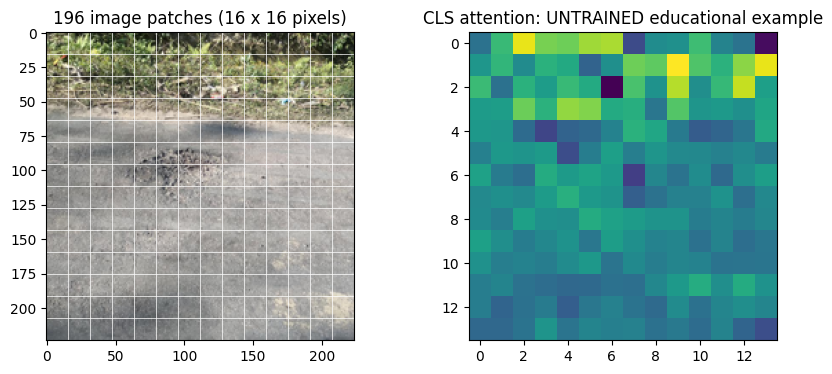

In [14]:
# 교육용 작은 ViT 구성 요소 — 실제 RT-DETR 학습과 별개
import matplotlib.pyplot as plt
from torch import nn
from PIL import Image
import json
source = json.loads((Path(RUN_ROOT) / 'source_manifest.json').read_text())
sample_path = Path(DATA_ROOT) / source[0]['relative_path']
rgb = np.asarray(Image.open(sample_path).convert('RGB').resize((224,224))).copy()
x = torch.tensor(rgb).permute(2,0,1).unsqueeze(0).float() / 255.0
PATCH, D, HEADS = 16, 96, 4
# CPU 난수만 격리; 뒤의 fold 학습 seed에는 영향을 주지 않음.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)
    patches = nn.Unfold(kernel_size=PATCH, stride=PATCH)(x).transpose(1,2)
    tokens = nn.Linear(3*PATCH*PATCH, D)(patches)
    cls = nn.Parameter(torch.zeros(1,1,D))
    seq = torch.cat([cls, tokens], dim=1)
    position = nn.Parameter(torch.randn(1,seq.shape[1],D)*0.02)
    seq_with_position = seq + position
    attention = nn.MultiheadAttention(D, HEADS, batch_first=True)
    attended, weights = attention(seq_with_position, seq_with_position, seq_with_position,
                                   need_weights=True, average_attn_weights=False)
print('이미지:', tuple(x.shape))
print('펼친 패치:', tuple(patches.shape))
print('패치 토큰:', tuple(tokens.shape), '| CLS+position:', tuple(seq_with_position.shape))
print('Attention 가중치 [batch,head,query,key]:', tuple(weights.shape))
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(rgb)
for n in range(0,225,PATCH):
    axes[0].axhline(n-.5,color='white',lw=.5); axes[0].axvline(n-.5,color='white',lw=.5)
axes[0].set_title('196 image patches (16 x 16 pixels)')
heat = weights[0,:,0,1:].mean(0).detach().numpy().reshape(14,14)
axes[1].imshow(heat,cmap='viridis'); axes[1].set_title('CLS attention: UNTRAINED educational example')
plt.show(); plt.close(fig)
del attention, attended, weights, patches, tokens, seq, seq_with_position, cls, position

## 셀 7 — 분류 출력과 객체 검출 출력은 다릅니다

| 모델/출력 | 예시 shape | 의미 |
|---|---|---|
| 이미지 분류 logits | `[B, 2]` | 이미지 전체의 배경/포트홀 점수. 박스 위치는 없음 |
| 검출 box head | `[B, Q, 4]` | Q개 후보의 좌표 |
| 검출 class head | `[B, Q, C]` | 후보별 클래스 점수. 모델에 따라 배경 처리/정규화 방식이 다름 |
| 최종 검출 결과 | 이미지마다 `[N, 6]` | `x1, y1, x2, y2, score, class_id` |

분류 ViT 뒤에 분류 head만 달면 박스 좌표를 얻을 수 없습니다. 검출에는 공간 특징과 박스/클래스 head, 여러 객체를 정답과 연결하는 학습 방법이 필요합니다. DETR 계열은 object query와 decoder를 사용하고 학습 시 일대일 할당을 사용합니다. 여기서 image patch token과 object query는 서로 다른 개념입니다.

포트홀이 단일 클래스여도 여러 객체와 배경이 존재하므로, 단순한 `softmax([pothole])=1`을 검출 점수로 사용할 수 없습니다. RT-DETR의 실제 클래스 출력과 손실 처리는 라이브러리가 담당합니다. 아래 toy head는 **출력 모양만** 보여줍니다.

In [15]:
# 형태 설명용 예제. 무작위 숫자는 성능 결과가 아닙니다.
B, Q, D, C = 1, 300, 96, 1
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(1)
    image_feature = torch.randn(B,D)
    cls_logits = nn.Linear(D,2)(image_feature)
    query_features = torch.randn(B,Q,D)
    boxes_cxcywh = nn.Linear(D,4)(query_features).sigmoid()
    object_scores = nn.Linear(D,C)(query_features).sigmoid()
print('분류 logits:', tuple(cls_logits.shape))
print('검출 normalized cxcywh:', tuple(boxes_cxcywh.shape))
print('검출 클래스 점수:', tuple(object_scores.shape))
del image_feature, cls_logits, query_features, boxes_cxcywh, object_scores

분류 logits: (1, 2)
검출 normalized cxcywh: (1, 300, 4)
검출 클래스 점수: (1, 300, 1)


## 셀 8 — 선택 사항인 시험 학습은 기본 OFF
이미 시험 실행을 완료했으므로 `RUN_SMOKE_TEST=False`로 건너뜁니다. 실제 비교 학습은 셀 9·11의 100 epoch 설정입니다.

새 GPU 환경에서 학습·저장·재개를 먼저 확인하고 싶을 때만 True로 바꾸세요. 별도 smoke 폴더에서 3 epoch를 수행하고 outer test는 사용하지 않습니다.


In [16]:
RUN_SMOKE_TEST = False
if RUN_SMOKE_TEST:
    SMOKE_CTX, SMOKE_RESULT = week6_rtdetr.smoke_test(CTX, epochs=3)
    assert SMOKE_RESULT['resume_verified']['start_epoch_zero_based'] >= 1
else:
    print('3-epoch 시험 학습 생략. 본 학습 예산:', CTX['cfg']['epochs'], 'epoch')

3-epoch 시험 학습 생략. 본 학습 예산: 100 epoch


## 셀 9 — GPU에서 Fold 1 본 학습 또는 재개
GPU에서 Fold 1을 시작합니다. 각 epoch가 끝나면 last.pt·best.pt·진행 상태를 Drive에 저장합니다. 학습률 일정과 총 예산은 100 epoch입니다.

`SESSION_EPOCHS`에 도달하면 저장 후 돌아오며 같은 셀이나 셀 11로 이어갑니다. 기본 None이면 완료까지 계속합니다. 런타임 중단 시 마지막 저장 epoch 이후 작업은 다시 수행합니다.

이 셀을 먼저 실행한 경우 셀 11은 같은 Fold 1의 진행 상태를 확인한 뒤 이어갑니다. 실제 소요 시간과 VRAM 사용량은 현재 GPU에서 측정합니다.


fold1: 공통 COCO 사전학습 가중치에서 새로 학습
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/week6_cv_staging_gpu_v4/fd7fae85f3a5e32a/fold1/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Pothole/week6_rtdetr_results

,fold,best_sha256,epochs_completed,logged_wall_seconds,recovered_after_finalization,peak_allocated_gib_last_session,device,cpu_threads,epoch_budget,patience
0,1,60a2e6f556ccfb8c4e70ffa4258bb777c2fe8a6b297d0c...,100,13430.112889,False,3.826721,0,2,100,0


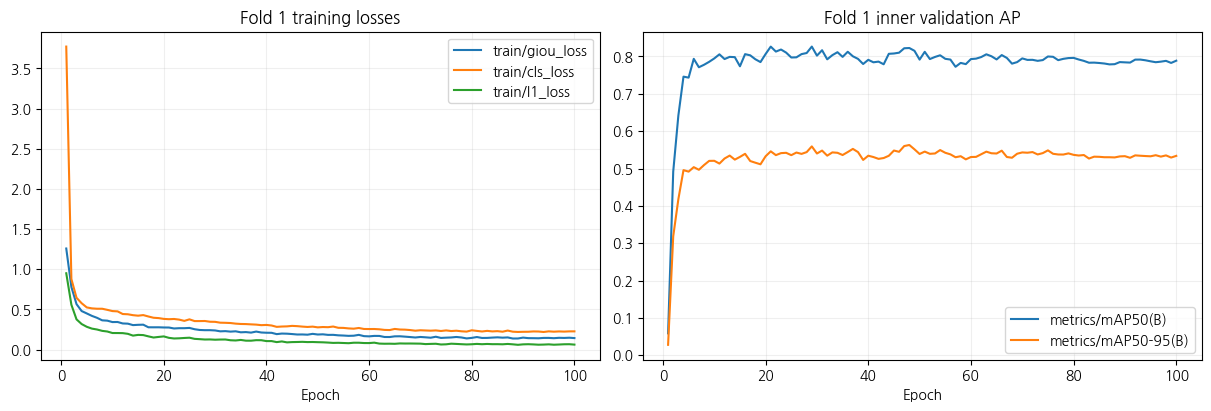

In [17]:
BEST_FOLD1 = week6_rtdetr.train_session(CTX, 1, max_new_epochs=SESSION_EPOCHS)
if BEST_FOLD1 is None:
    print('Fold 1은 저장 후 일시정지 상태입니다. 셀 9 또는 11로 계속 실행하세요.')
else:
    print('Fold 1 본 학습 완료:', BEST_FOLD1)
display(week6_rtdetr.training_summary(CTX))
csv_path = OUT / 'fold1/detector/results.csv'
if csv_path.is_file():
    log = pd.read_csv(csv_path)
    log.columns = log.columns.str.strip()
    plt = week6_rtdetr.plotting()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for col in [c for c in log if c.startswith('train/') and 'loss' in c]:
        axes[0].plot(log['epoch'], log[col], label=col)
    for col in [c for c in log if 'mAP' in c]:
        axes[1].plot(log['epoch'], log[col], label=col)
    for ax, title in zip(axes, ['Fold 1 training losses', 'Fold 1 inner validation AP']):
        ax.set(title=title, xlabel='Epoch'); ax.grid(alpha=.2)
        if ax.lines: ax.legend()
    plt.show(); plt.close(fig)

## 셀 10 — 완료된 Fold 1의 공통 GPU 평가
기존 YOLO와 RT-DETR을 같은 GPU·Ultralytics 환경에서 다시 추론합니다. 각 모델의 inner validation에서 F1 임계값을 고정하고 outer test를 평가합니다. AP는 낮은 confidence의 전체 후보를 사용합니다.

학습이 미완료이면 평가를 보류합니다. Fold 1 outer 결과를 보고 학습 설정을 선택하지 마세요. 설정 탐색은 train·inner validation 안에서 수행합니다.


In [18]:
if week6_rtdetr.training_finished(CTX, 1):
    if not week6_rtdetr.completed(CTX, 1):
        week6_rtdetr.evaluate_fold(CTX, 1)
    week6_rtdetr.pilot_status(CTX)
else:
    print('Fold 1 본 학습 미완료: outer 평가는 보류합니다. 셀 9 또는 11로 재개하세요.')

  추론 20/96
  추론 40/96
  추론 60/96
  추론 80/96
  추론 96/96
  추론 20/120
  추론 40/120
  추론 60/120
  추론 80/120
  추론 100/120
  추론 120/120
fold1 YOLOv8: mAP50–95=0.4532, F1=0.6945, threshold=0.560
  추론 20/96
  추론 40/96
  추론 60/96
  추론 80/96
  추론 96/96
  추론 20/120
  추론 40/120
  추론 60/120
  추론 80/120
  추론 100/120
  추론 120/120
fold1 RT-DETR: mAP50–95=0.5429, F1=0.7508, threshold=0.550
Fold1 학습 기록: {'best_sha256': '60a2e6f556ccfb8c4e70ffa4258bb777c2fe8a6b297d0c4b8d36ddad75612fbd', 'epochs_completed': 100, 'logged_wall_seconds': 13430.112889223, 'recovered_after_finalization': False, 'peak_allocated_gib_last_session': 3.826720714569092, 'device': '0', 'cpu_threads': 2, 'epoch_budget': 100, 'patience': 0}


,fold,model,threshold,val_f1,parameters,images,map,map_50,map_75,map_small,map_medium,map_large,precision,recall,f1,tp,fp,fn,fp_per_image
0,1,YOLOv8,0.56,0.702913,11135987,120,0.453232,0.714140,0.507617,0.180857,0.404727,0.594212,0.779592,0.626230,0.694545,191,54,114,0.450000
1,1,RT-DETR,0.55,0.793419,32808131,120,0.542906,0.793608,0.628143,0.240963,0.471646,0.694709,0.760943,0.740984,0.750831,226,71,79,0.591667


전체 실행은 fold1을 건너뛰고 나머지를 학습합니다. fold1 결과를 보고 설정을 바꾸면 새 EXPERIMENT_NAME을 사용하세요.


## 셀 11 — 같은 설정의 5-fold 본 학습·평가
`FOLDS_TO_RUN`에 지정한 fold를 진행합니다. 완료 fold는 검증 후 건너뛰고, 미완료 fold는 last.pt부터 재개합니다. 각 fold는 독립적으로 같은 사전학습 가중치에서 시작합니다.

`SESSION_EPOCHS`가 지정돼 있으면 현재 fold에서 해당 수의 새 epoch를 저장한 뒤 돌아옵니다. 학습 미완료 fold의 outer test를 평가하거나 다음 fold로 넘어가지 않습니다. 같은 셀을 반복 실행해 누적 100 epoch에 도달하면 평가하고 다음 fold로 진행합니다.

런타임이 끊기면 셀 1~5를 실행한 뒤 이 셀을 실행하세요. 같은 패키지·코드·설정·실험 이름을 유지해야 합니다. 일부 fold 결과는 중간 결과이며 5-fold 최종 결과로 표시하지 않습니다.

In [19]:
FOLD_RESULTS = week6_rtdetr.run(CTX, folds=FOLDS_TO_RUN, max_new_epochs=SESSION_EPOCHS)
if not FOLD_RESULTS.empty:
    display(FOLD_RESULTS)
print('평가 완료 fold:', [k for k in range(1,6) if week6_rtdetr.completed(CTX,k)])

fold1: 학습·평가 완료 → 건너뜀

Fold 2/5 | train=382 inner_val=96 outer_test=120
fold2: 공통 COCO 사전학습 가중치에서 새로 학습
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/week6_cv_staging_gpu_v4/fd7fae85f3a5e32a/fold2/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

,fold,model,threshold,val_f1,parameters,images,map,map_50,map_75,map_small,map_medium,map_large,precision,recall,f1,tp,fp,fn,fp_per_image
0,1,YOLOv8,0.56,0.702913,11135987,120,0.453232,0.714140,0.507617,0.180857,0.404727,0.594212,0.779592,0.626230,0.694545,191,54,114,0.450000
1,1,RT-DETR,0.55,0.793419,32808131,120,0.542906,0.793608,0.628143,0.240963,0.471646,0.694709,0.760943,0.740984,0.750831,226,71,79,0.591667
2,2,YOLOv8,0.31,0.670330,11135987,120,0.440435,0.715935,0.481136,0.374011,0.346762,0.541160,0.732143,0.648221,0.687631,164,60,89,0.500000
3,2,RT-DETR,0.63,0.756646,32808131,120,0.526819,0.782225,0.554302,0.329148,0.393977,0.685928,0.874346,0.660079,0.752252,167,24,86,0.200000
4,3,YOLOv8,0.50,0.705882,11135987,120,0.444249,0.741807,0.472128,0.305628,0.427737,0.549643,0.785992,0.633229,0.701389,202,55,117,0.458333
5,3,RT-DETR,0.49,0.741228,32808131,120,0.557310,0.855114,0.644512,0.439201,0.522617,0.658974,0.782209,0.799373,0.790698,255,71,64,0.591667
6,4,YOLOv8,0.62,0.745690,11135987,119,0.466399,0.736467,0.532023,0.331090,0.450749,0.606297,0.874539,0.640541,0.739470,237,34,133,0.285714
7,4,RT-DETR,0.53,0.778947,32808131,119,0.519268,0.800760,0.589970,0.403728,0.471203,0.684942,0.796657,0.772973,0.784636,286,73,84,0.613445
8,5,YOLOv8,0.38,0.693487,11135987,119,0.454343,0.736208,0.491490,0.321399,0.449523,0.587142,0.740506,0.690265,0.714504,234,82,105,0.689076
9,5,RT-DETR,0.48,0.750890,32808131,119,0.520881,0.790096,0.567775,0.378967,0.510135,0.647728,0.736390,0.758112,0.747093,257,92,82,0.773109


평가 완료 fold: [1, 2, 3, 4, 5]


## 셀 12 — ⑥ 성능표·fold 그래프·PR·학습 곡선
**출력:** `fold_metrics.csv`, `summary_mean_std.csv`, `paired_differences.csv`, `figures/`.

- mAP50–95는 IoU 0.50~0.95 간격 0.05의 COCO AP 평균, mAP50/75는 각 IoU의 AP입니다. maxDet=300을 직접 선택해 과거 map=-1 집계 문제를 피합니다.
- P/R/F1은 inner-val에서 고정한 threshold, IoU=0.50, 점수순 일대일 매칭입니다.
- AP/PR은 conf=0.001 이상으로 수집한 후보를 사용합니다. 이 수집 기준 아래 후보는 포함하지 않습니다.
- PR은 IoU=0.50의 COCO 101지점 보간 곡선입니다. AP와 운영 threshold의 한 점은 다른 정보입니다.
- 크기별 AP의 -1은 해당 GT가 없어 정의되지 않은 경우입니다. 평균에서 제외하고 `valid_folds`를 기록합니다. 작은 객체의 기준은 원본 GT 면적입니다.
- fold 평균±표본 SD는 기술 통계입니다. 학습 데이터가 겹치는 5개 fold를 독립 seed 반복으로 해석하지 않습니다.

완료 fold [1, 2, 3, 4, 5]; 5-fold 결과입니다.


,fold,model,parameters,threshold,map,map_50,map_75,map_small,precision,recall,f1,tp,fp,fn,fp_per_image
0,1,YOLOv8,11135987,0.56,0.453232,0.714140,0.507617,0.180857,0.779592,0.626230,0.694545,191,54,114,0.450000
1,1,RT-DETR,32808131,0.55,0.542906,0.793608,0.628143,0.240963,0.760943,0.740984,0.750831,226,71,79,0.591667
2,2,YOLOv8,11135987,0.31,0.440435,0.715935,0.481136,0.374011,0.732143,0.648221,0.687631,164,60,89,0.500000
3,2,RT-DETR,32808131,0.63,0.526819,0.782225,0.554302,0.329148,0.874346,0.660079,0.752252,167,24,86,0.200000
4,3,YOLOv8,11135987,0.50,0.444249,0.741807,0.472128,0.305628,0.785992,0.633229,0.701389,202,55,117,0.458333
5,3,RT-DETR,32808131,0.49,0.557310,0.855114,0.644512,0.439201,0.782209,0.799373,0.790698,255,71,64,0.591667
6,4,YOLOv8,11135987,0.62,0.466399,0.736467,0.532023,0.331090,0.874539,0.640541,0.739470,237,34,133,0.285714
7,4,RT-DETR,32808131,0.53,0.519268,0.800760,0.589970,0.403728,0.796657,0.772973,0.784636,286,73,84,0.613445
8,5,YOLOv8,11135987,0.38,0.454343,0.736208,0.491490,0.321399,0.740506,0.690265,0.714504,234,82,105,0.689076
9,5,RT-DETR,32808131,0.48,0.520881,0.790096,0.567775,0.378967,0.736390,0.758112,0.747093,257,92,82,0.773109


,model,metric,mean,std_ddof1,folds,valid_folds
0,YOLOv8,map,0.451732,0.010097,5,5
1,YOLOv8,map_50,0.728911,0.012876,5,5
2,YOLOv8,precision,0.782554,0.056549,5,5
3,YOLOv8,recall,0.647697,0.025168,5,5
4,YOLOv8,f1,0.707508,0.020439,5,5
5,YOLOv8,fp_per_image,0.476625,0.144198,5,5
6,YOLOv8,map_75,0.496879,0.023664,5,5
7,YOLOv8,map_small,0.302597,0.072621,5,5
8,YOLOv8,map_medium,0.415900,0.042983,5,5
9,YOLOv8,map_large,0.575691,0.028643,5,5


완료 fold [1, 2, 3, 4, 5]; 5-fold 결과입니다.


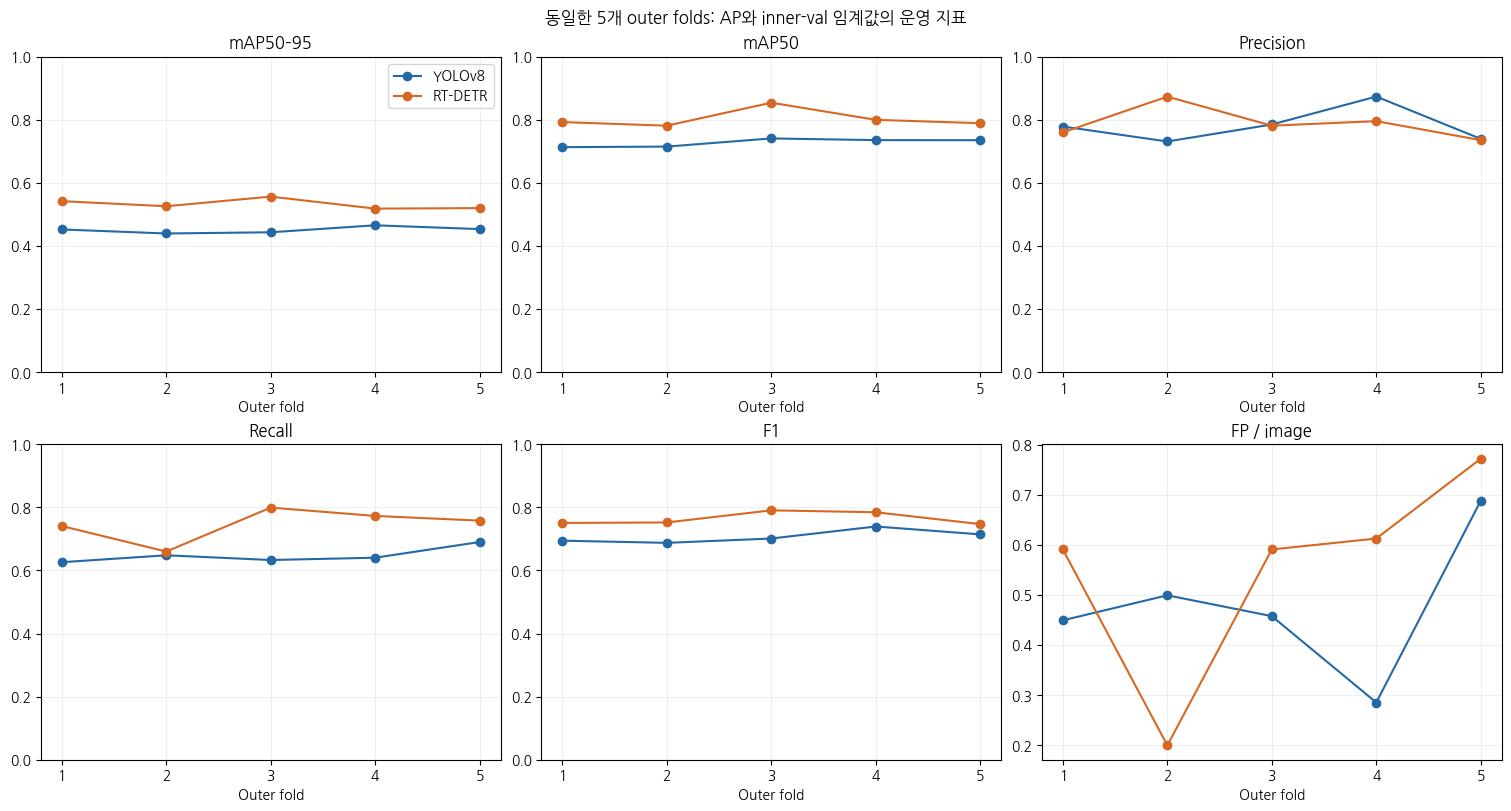

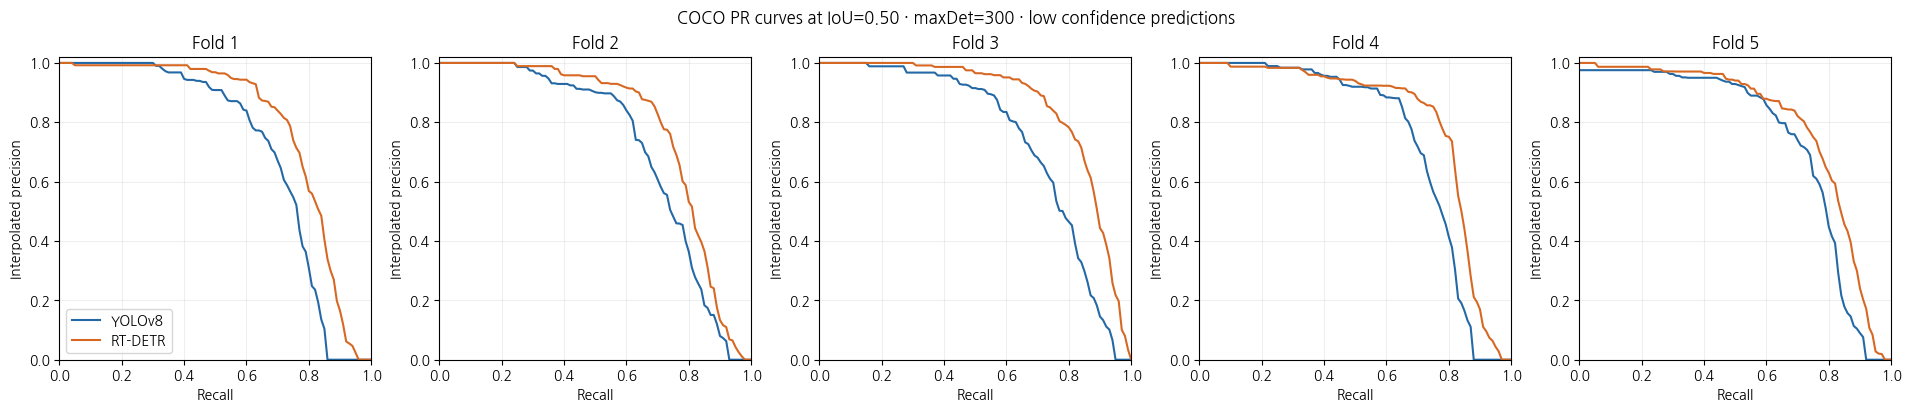

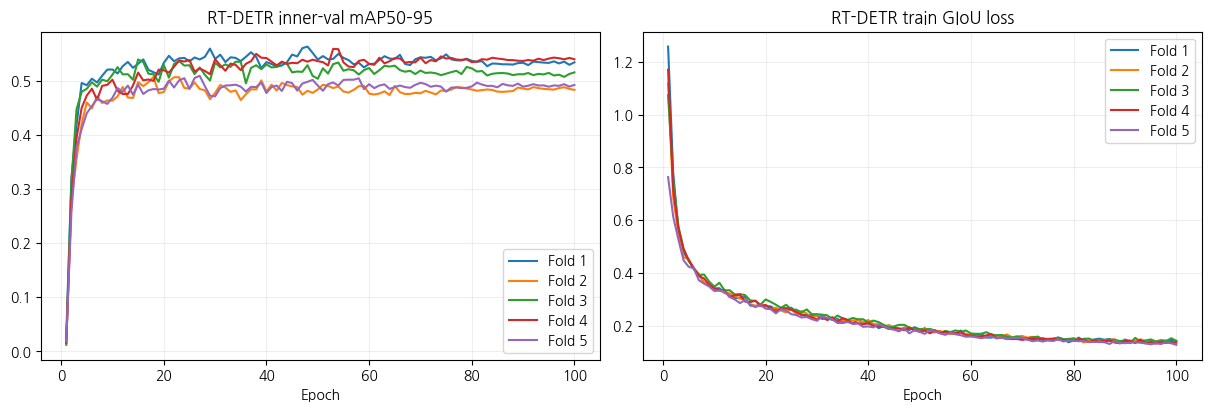

mean           std_ddof1          
model          RT-DETR    YOLOv8   RT-DETR    YOLOv8
metric                                              
f1            0.765102  0.707508  0.020796  0.020439
fp_per_image  0.553978  0.476625  0.211953  0.144198
map           0.533437  0.451732  0.016293  0.010097
map_50        0.804361  0.728911  0.029146  0.012876
map_75        0.596940  0.496879  0.038581  0.023664
map_large     0.674456  0.575691  0.020036  0.028643
map_medium    0.473916  0.415900  0.050215  0.042983
map_small     0.358401  0.302597  0.076899  0.072621
precision     0.790109  0.782554  0.052291  0.056549
recall        0.746304  0.647697  0.052749  0.025168

평균 ± 표본 SD는 fold 간 기술 통계입니다. 5개 fold는 학습 데이터가 겹치므로 독립 반복실험이 아닙니다.


In [20]:
DONE_FOLDS = [k for k in range(1,6) if week6_rtdetr.completed(CTX,k)]
if DONE_FOLDS:
    FOLD_RESULTS = week6_rtdetr.summarize(CTX, require_all=len(DONE_FOLDS)==5)
    display(FOLD_RESULTS[['fold','model','parameters','threshold','map','map_50','map_75','map_small',
                          'precision','recall','f1','tp','fp','fn','fp_per_image']])
if len(DONE_FOLDS)==5:
    display(pd.read_csv(OUT/'summary_mean_std.csv'))
    week6_rtdetr.make_plots(CTX)
else:
    print('5-fold 최종 그래프 보류. 현재 완료 fold:', DONE_FOLDS, '| 셀 11에서 계속 실행하세요.')

## 셀 13 — 성공·실패 비교: 5유형 × 최대 3장
**출력:** `cases/*.png`, `case_index.csv`, `case_population.csv`.

1. RT-DETR이 새로 검출한 GT
2. RT-DETR이 놓친 GT
3. YOLO가 맞힌 GT를 유지하면서 RT-DETR 오탐 감소
4. RT-DETR 오탐 증가
5. 두 모델 모두 놓친 GT

GT/YOLO/RT-DETR 박스를 나란히 그리고 IoU 부족·threshold 미달·중복 검출 등 **수치로 확인되는 이유를 이미지에 표시**합니다. 실제 사례가 없는 유형은 0건으로 출력합니다. 유형당 최대 3장을 고정 seed로 선택하며 한 이미지가 다른 유형에도 포함될 수 있습니다. 선택 사례를 전체 성공률로 해석하지 마세요. 조명·그림자 같은 시각적 원인은 수작업 검토 항목입니다.

In [21]:
if all(week6_rtdetr.completed(CTX,k) for k in range(1,6)):
    CASE_POPULATION = week6_rtdetr.make_cases(CTX, per_type=3)
    display(CASE_POPULATION)
else:
    print('사례 비교는 5-fold 완료 후 이 셀을 실행하세요.')

Output hidden; open in https://colab.research.google.com to view.

## 셀 14 — 같은 GPU에서 속도 재측정
YOLOv8과 RT-DETR을 같은 GPU·세션에서 batch 1, FP32로 측정합니다. 워밍업 후 CUDA 동기화로 연산 완료를 기다린 뒤 시간을 기록합니다.

AP 후보 임계값, 공통 confidence 0.25, 모델별 inner-val 선택 임계값의 세 조건을 비교합니다. 기존 CPU 속도나 5주차의 과거 속도를 합산하지 않습니다. 별도 TensorRT FP16 결과와 측정 조건이 다릅니다.


In [1]:
SPEED_OUT = None
if all(week6_rtdetr.completed(CTX,k) for k in range(1,6)):
    SPEED_OUT, SPEED_SUMMARY = week6_rtdetr.benchmark(
        CTX, folds=[1,2,3,4,5], images=30, repeats=3, warmup=10)
    display(SPEED_SUMMARY)
    week6_rtdetr.plot_speed(SPEED_OUT)
else:
    print('GPU 속도 비교는 5-fold 완료 후 실행하세요.')


NameError: name 'week6_rtdetr' is not defined

## 셀 15 — 실제 결과로 보고서 생성
**출력:** `report/week6_report.html`, `report/week6_report.md`.

HTML에는 표·성능 그래프·선정 사례 이미지가 포함되어 브라우저에서 열 수 있습니다. Markdown은 GitHub용으로 활용할 수 있으며 그림은 상대 경로이므로 관련 figures/cases 폴더도 함께 옮겨야 합니다. 보고서는 실제 관찰된 차이만 적고 성능 우열이나 실패의 시각적 원인을 만들어내지 않습니다.

속도 셀을 건너뛴 경우 보고서에 속도 미측정으로 표시합니다. 다른 세션의 오래된 속도를 자동 선택하지 않습니다.

In [ ]:
if all(week6_rtdetr.completed(CTX,k) for k in range(1,6)):
    REPORT_DIR = week6_rtdetr.export_report(CTX, speed_dir=globals().get('SPEED_OUT'))
    print('HTML:', REPORT_DIR/'week6_report.html')
    print('Markdown:', REPORT_DIR/'week6_report.md')
else:
    print('5-fold 결과가 모두 생성되면 최종 보고서를 만듭니다. 먼저 셀 11을 이어서 실행하세요.')

## 셀 16 — 결과 파일과 현재 진행 상태 확인
**목적:** 학습을 다시 돌리지 않고 저장된 완료 상태를 확인합니다. **출력:** fold별 학습/평가 여부와 주요 파일 존재.

경로 오류이면 `RUN_ROOT`와 원본 목록을 확인하고, hash 불일치는 데이터·코드·가중치가 바뀌었는지 확인하세요. 설정을 바꿔 재실험하려면 새 `EXPERIMENT_NAME`을 사용합니다. 큰 GT 오류를 삭제하거나 검사만 우회해서 계속하지 마세요. OOM은 새 실험명+낮은 batch로 점검하고, NaN은 해당 fold의 `last_error.json`과 학습 로그를 확인합니다. 준비 셀은 통과했지만 학습이 오래 걸리면 `training_progress.json`의 epoch와 `results.csv` 갱신을 확인하세요.

In [24]:
status = []
for k in range(1,6):
    folder = OUT/f'fold{k}'
    progress = week6_rtdetr.load(folder/'training_progress.json') if (folder/'training_progress.json').exists() else {}
    status.append({'fold':k, 'saved_epoch':progress.get('epoch',0), 'epoch_budget':CTX['cfg']['epochs'],
                   'status':progress.get('status','not_started'),
                   'last_checkpoint':(folder/'detector/weights/last.pt').is_file(),
                   'train_complete':week6_rtdetr.training_finished(CTX,k),
                   'evaluation_complete':week6_rtdetr.completed(CTX,k)})
display(pd.DataFrame(status))
print('실행 장치:', CTX['cfg']['device'], '| CPU threads:', CTX['cfg']['cpu_threads'])
print('결과 폴더:', OUT)
print('재접속 후 셀 1~5 → 셀 11. 총 EPOCHS는 줄이지 말고 같은 설정으로 재개하세요.')

,fold,saved_epoch,epoch_budget,status,last_checkpoint,train_complete,evaluation_complete
0,1,100,100,completed,True,True,True
1,2,100,100,completed,True,True,True
2,3,100,100,completed,True,True,True
3,4,100,100,completed,True,True,True
4,5,100,100,completed,True,True,True


실행 장치: 0 | CPU threads: 2
결과 폴더: /content/drive/MyDrive/Pothole/week6_rtdetr_results/week6_rtdetr_gpu_full100_v4
재접속 후 셀 1~5 → 셀 11. 총 EPOCHS는 줄이지 말고 같은 설정으로 재개하세요.


## 참고 자료와 검증 범위
- RT-DETR 원 논문: https://arxiv.org/abs/2304.08069
- Ultralytics GPU 장치·학습·재개: https://docs.ultralytics.com/modes/train/
- RT-DETR CUDA 학습 주의사항: https://docs.ultralytics.com/models/rtdetr/
- COCO 평가기: https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py

**검증 범위:** 노트북 문법·내장 소스 일치와 COCO 평가기의 합성 예제, 데이터 분할·평가 집계를 검사했습니다. 모의 CUDA 환경에서 GPU 장치 전달, GPU 부재 오류, 100-epoch 예산을 유지한 분할 재개, FP32 추론과 CUDA 동기화 호출을 확인했습니다.

코드를 수정한 환경에는 PyTorch/CUDA가 없어 실제 RT-DETR GPU 순전파·역전파와 5-fold 학습은 실행하지 못했습니다. 실제 GPU 메모리와 학습 시간은 Colab에서 확인해야 합니다. batch 2가 부족하면 새 실험명으로 batch 1을 사용하세요.
